In [48]:
import os
import sys
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from matplotlib import rcParams

# Set publication style
rcParams['font.family'] = 'Arial'

# ── Path setup ────────────────────────────────────────────────────────────
GLM_DIR = '/Users/akhilbandi/Documents/Portfolio/code_projects/Context Paper Code/GLM_encoding_model'
if GLM_DIR not in sys.path:
    sys.path.insert(0, GLM_DIR)

from core.session_pipeline import BASE_DATA_PATH, MODEL_1_DIR

# ── Plot style ─────────────────────────────────────────────────────────────
rcParams['font.family']         = 'Arial'
rcParams['axes.spines.right']   = False
rcParams['axes.spines.top']     = False
rcParams['axes.labelsize']      = 8
rcParams['xtick.labelsize']     = 7
rcParams['ytick.labelsize']     = 7

# ── Constants ──────────────────────────────────────────────────────────────
CONTEXT_NAMES = {0: 'CG', 1: 'Visual', 2: 'Audio'}
CTX_COLORS    = {0: 'purple', 1: '#EC008C', 2: '#27AAE1'}

# Canonical predictor group order and display labels
GROUP_ORDER = [
    'position_only',
    'audio_context', 'audio_stim',
    'visual_context', 'visual_stim',
    'velocity',
    'choice_spatial',
    'turn_onset',
    'outcome',
]
GROUP_LABELS = {
    'position_only':  'Position',
    'audio_context':  'Audio\nContext',
    'audio_stim':     'Audio\nStim',
    'visual_context': 'Visual\nContext',
    'visual_stim':    'Visual\nStim',
    'velocity':       'Velocity',
    'choice_spatial': 'Choice\nSpatial',
    'turn_onset':     'Turn\nOnset',
    'outcome':        'Outcome',
}
GROUP_COLORS = {
    'position_only':  '#9B59B6',
    'audio_context':  '#27AAE1',
    'audio_stim':     '#1A7AAF',
    'visual_context': '#EC008C',
    'visual_stim':    '#A8005E',
    'velocity':       '#2ECC71',
    'choice_spatial': '#E67E22',
    'turn_onset':     '#E74C3C',
    'outcome':        '#F39C12',
    'mixed':          '#95A5A6',
    'unclassified':   '#BDC3C7',
}
# String-keyed context colours (used by per-context analysis plots)
CTX_COLORS_STR = {'cg': '#9B59B6', 'visual': '#EC008C', 'audio': '#27AAE1'}

print('✓ Imports complete')

✓ Imports complete


In [ ]:
# ── Session registry ──────────────────────────────────────────────────────
# Keys: mouse_ID  |  Values: list of recording dates

PPC_AVC = {
    'IS-2-1L': ['2025-03-10', '2025-03-11', '2025-03-12', '2025-03-13',
                '2025-03-20', '2025-03-26', '2025-04-02', '2025-04-04',
                '2025-04-08', '2025-04-09', '2025-05-05', '2025-05-27',
                '2025-05-28', '2025-05-30', '2025-11-20'],
    'IS-3-1R': ['2024-12-23', '2024-12-24'],
    'JP-2-1L': ['2025-08-19', '2025-08-26', '2025-09-16', '2025-09-17',
                '2025-09-19', '2025-09-22'],
    'KA-1-00': ['2025-12-16', '2026-01-08'],
    'KA-2-00': ['2026-01-08', '2026-01-13', '2026-01-14', '2026-01-28'],
    'KO-5-1L': ['2026-03-05', '2026-03-06', '2026-03-12', '2026-03-13', '2026-03-24'],
    'KO-6-00': ['2026-03-12', '2026-03-23', '2026-03-25']
}

In [50]:
EXPECTED_LESION_GROUPS = [
    'position_only', 'audio_context', 'audio_stim',
    'visual_context', 'visual_stim', 'velocity',
    'choice_spatial', 'turn_onset', 'outcome',
]

def check_session_results(mouse_ID, date):
    """
    Inspect the Model_1_results folder and return which outputs already exist.

    Returns
    -------
    dict with keys:
        'full_model'    : bool  — glm_M1_full.pkl present
        'lesion_groups' : dict  — {group_name: bool} for each expected group
        'lesion_all'    : bool  — glm_M1_lesion_all.pkl present
        'all_complete'  : bool  — full model + all lesion files present
        'missing_lesion_groups' : list of str  — groups whose pkl is absent
    """
    res_dir = os.path.join(BASE_DATA_PATH, mouse_ID, date, 'Model_1_results')
    full_done = os.path.exists(os.path.join(res_dir, 'glm_M1_full.pkl'))
    all_done  = os.path.exists(os.path.join(res_dir, 'glm_M1_lesion_all.pkl'))
    lesion_done = {
        g: os.path.exists(os.path.join(res_dir, f'glm_M1_lesion_{g}.pkl'))
        for g in EXPECTED_LESION_GROUPS
    }
    missing = [g for g, done in lesion_done.items() if not done]
    return {
        'full_model':            full_done,
        'lesion_groups':         lesion_done,
        'lesion_all':            all_done,
        'all_complete':          full_done and all_done and not missing,
        'missing_lesion_groups': missing,
    }

completed_sessions = {}
for mouse_ID, dates in PPC_AVC.items():
    for date in dates:
        status = check_session_results(mouse_ID, date)
        if status['all_complete']:
            completed_sessions.setdefault(mouse_ID, []).append(date)

print(f"Completed: {sum(len(v) for v in completed_sessions.values())} / "
      f"{sum(len(v) for v in PPC_AVC.values())} sessions")
for mouse, dates in completed_sessions.items():
    print(f"  {mouse}: {dates}")

Completed: 33 / 37 sessions
  IS-2-1L: ['2025-03-10', '2025-03-11', '2025-03-12', '2025-03-20', '2025-03-26', '2025-04-02', '2025-04-04', '2025-04-08', '2025-04-09', '2025-05-05', '2025-05-27', '2025-05-28', '2025-05-30', '2025-11-20']
  IS-3-1R: ['2024-12-23', '2024-12-24']
  JP-2-1L: ['2025-08-19', '2025-08-26', '2025-09-16', '2025-09-17', '2025-09-19', '2025-09-22']
  KA-1-00: ['2025-12-16', '2026-01-08']
  KA-2-00: ['2026-01-08', '2026-01-13', '2026-01-14', '2026-01-28']
  KO-5-1L: ['2026-03-05', '2026-03-06', '2026-03-12', '2026-03-13']
  KO-6-00: ['2026-03-12']


In [ ]:
PPC_AVC = {
    'IS-2-1L': ['2025-03-10', '2025-03-11', '2025-03-12', '2025-03-13',
                '2025-03-20', '2025-03-26', '2025-04-02', '2025-04-04',
                '2025-04-08', '2025-04-09', '2025-05-05',
                '2025-05-28', '2025-05-30', '2025-11-20'],
    'IS-3-1R': ['2024-12-23', '2024-12-24'],
    'JP-2-1L': ['2025-08-19', '2025-08-26', '2025-09-16', '2025-09-17',
                '2025-09-19', '2025-09-22'],
    'KA-1-00': ['2025-12-16', '2026-01-08'],
    'KA-2-00': ['2026-01-08', '2026-01-13', '2026-01-14'],
    'KO-5-1L': ['2026-03-05', '2026-03-06', '2026-03-12', '2026-03-13'],
    'KO-6-00': ['2026-03-12', '2026-03-23'],
}

total = sum(len(v) for v in PPC_AVC.values())
print(f'Session registry: {len(PPC_AVC)} mice | {total} sessions total')

Session registry: 7 mice | 32 sessions total


In [12]:
def load_session_results(sessions_dict):
    """
    Load full model and lesion results for every session.

    Reads from:
        {BASE_DATA_PATH}/{mouse_ID}/{date}/{MODEL_1_DIR}/glm_M1_full.pkl
        {BASE_DATA_PATH}/{mouse_ID}/{date}/{MODEL_1_DIR}/glm_M1_lesion_all.pkl

    Returns
    -------
    sessions : list of dicts, each with keys:
        mouse_ID, date, full_res, lesion_res
        (lesion_res is None if the lesion file is missing)
    """
    sessions = []
    n_full_ok = n_lesion_ok = 0

    for mouse_ID, dates in sessions_dict.items():
        for date in dates:
            res_dir     = os.path.join(BASE_DATA_PATH, mouse_ID, date, MODEL_1_DIR)
            full_path   = os.path.join(res_dir, 'glm_M1_full.pkl')
            lesion_path = os.path.join(res_dir, 'glm_M1_lesion_all.pkl')

            if not os.path.exists(full_path):
                print(f'  [MISSING full]   {mouse_ID} / {date}')
                continue

            with open(full_path, 'rb') as f:
                full_res = pickle.load(f)
            n_full_ok += 1

            lesion_res = None
            if os.path.exists(lesion_path):
                with open(lesion_path, 'rb') as f:
                    lesion_res = pickle.load(f)
                n_lesion_ok += 1
            else:
                print(f'  [MISSING lesion] {mouse_ID} / {date}')

            n = full_res['test_frac_dev'].shape[0]
            print(f'  [OK] {mouse_ID} / {date}  ({n} neurons'
                  + ('' if lesion_res else '  — no lesion') + ')')
            sessions.append(dict(mouse_ID=mouse_ID, date=date,
                                 full_res=full_res, lesion_res=lesion_res))

    total = sum(len(v) for v in sessions_dict.values())
    print(f'\nLoaded {n_full_ok}/{total} sessions  '
          f'({n_lesion_ok} with lesion results)')
    return sessions


print('✓ load_session_results defined')

✓ load_session_results defined


In [13]:
def build_neuron_dataframe(
    sessions,
    responsiveness_threshold = 0.1,
    mixed_margin             = 0.5,
):
    """
    Build a per-neuron DataFrame across all sessions.

    Columns
    -------
    Identity:
        mouse_ID, date, neuron_idx
        n_neurons_session      — total neurons recorded in that session

    Full-model quality:
        test_frac_dev          — combined held-out fractional deviance
        cv_frac_dev            — cross-validated fractional deviance
        test_r2                — best-split trial-averaged R² (combined)
        frac_dev_cg / visual / audio   — per-context frac dev
        test_r2_cg / visual / audio    — per-context trial-averaged R²
        is_responsive          — test_frac_dev > responsiveness_threshold
        session_median_frac_dev — session-level QC: median test_frac_dev

    Weight norms (L2 norm of each group's weight block):
        w_norm_{group}         — magnitude of group's fitted weights

    Lesion contributions (delta = full − lesion, clipped at 0 for ranking):
        delta_fd_{group}       — unique contribution to frac dev
        delta_r2_{group}       — unique contribution to R²

    Classification (based on delta_fd ranking):
        dominant_group         — group with largest delta_fd
        dominant_delta         — its delta_fd value
        runner_up_group        — second largest group
        runner_up_delta        — its delta_fd value
        mixedness              — continuous score: runner_up / dominant (0=pure, 1=equal)
        is_mixed               — True when mixedness ≥ mixed_margin
        neuron_class           — dominant_group | 'mixed' | 'unclassified'

    Context selectivity:
        dominant_context       — context with highest frac_dev (cg/visual/audio)
        context_selectivity_idx — (best_ctx - 2nd_best) / best_ctx  [0=flat, 1=specific]

    Parameters
    ----------
    sessions                : list of session dicts from load_session_results
    responsiveness_threshold: float  — min test_frac_dev to be 'responsive'
    mixed_margin            : float  — mixedness threshold for 'mixed' label
                              (default 0.3: runner-up ≥ 30% of dominant delta)
    """
    FULL_REQUIRED = ['test_frac_dev', 'cv_frac_dev',
                     'test_frac_dev_per_ctx', 'test_trial_avg_r2']

    rows    = []
    skipped = []

    for s in sessions:
        mouse_ID   = s['mouse_ID']
        date       = s['date']
        full_res   = s['full_res']
        lesion_res = s['lesion_res']

        # ── Validate ────────────────────────────────────────────────────────
        missing = [k for k in FULL_REQUIRED if k not in full_res]
        if missing:
            skipped.append((mouse_ID, date, f'full_res missing: {missing}'))
            continue

        n_neurons = len(full_res['test_frac_dev'])
        if n_neurons == 0:
            skipped.append((mouse_ID, date, 'empty test_frac_dev'))
            continue

        # ── Lesion group names + delta arrays ──────────────────────────────
        if lesion_res is not None:
            group_names   = lesion_res['groups']
            delta_fd_dict = lesion_res['delta_frac_dev']   # group -> (n_neurons,)
            delta_r2_dict = lesion_res['delta_r2']
        else:
            group_names   = []
            delta_fd_dict = {}
            delta_r2_dict = {}

        # ── Per-context R² (may not exist in older result files) ───────────
        r2_per_ctx = full_res.get('test_trial_avg_r2_per_ctx', {})

        # ── Vectorised build — avoids slow per-neuron loop ─────────────────
        base = {
            'mouse_ID':              [mouse_ID] * n_neurons,
            'date':                  [date]     * n_neurons,
            'neuron_idx':            np.arange(n_neurons),
            'n_neurons_session':     n_neurons,
            # ── Full-model quality ──────────────────────────────────────────
            'test_frac_dev':         full_res['test_frac_dev'],
            'cv_frac_dev':           full_res['cv_frac_dev'],
            'test_r2':               full_res['test_trial_avg_r2'],
            # ── Per-context frac dev ────────────────────────────────────────
            'frac_dev_cg':           full_res['test_frac_dev_per_ctx'].get(0, np.zeros(n_neurons)),
            'frac_dev_visual':       full_res['test_frac_dev_per_ctx'].get(1, np.zeros(n_neurons)),
            'frac_dev_audio':        full_res['test_frac_dev_per_ctx'].get(2, np.zeros(n_neurons)),
            # ── Per-context trial-averaged R² ───────────────────────────────
            'test_r2_cg':            r2_per_ctx.get(0, np.full(n_neurons, np.nan)),
            'test_r2_visual':        r2_per_ctx.get(1, np.full(n_neurons, np.nan)),
            'test_r2_audio':         r2_per_ctx.get(2, np.full(n_neurons, np.nan)),
        }
        df_s = pd.DataFrame(base)

        # ── Per-group weight norms (L2 norm of each group's weight block) ──
        W           = full_res.get('weights')              # (n_features, n_neurons)
        pred_info   = full_res.get('predictor_info', {})
        if W is not None and pred_info:
            for grp, info in pred_info.items():
                s_col, e_col = info['start'], info['end']
                df_s[f'w_norm_{grp}'] = np.linalg.norm(W[s_col:e_col, :], axis=0)

        # ── Lesion delta columns ────────────────────────────────────────────
        for grp in group_names:
            df_s[f'delta_fd_{grp}'] = delta_fd_dict.get(grp, np.full(n_neurons, np.nan))
            df_s[f'delta_r2_{grp}'] = delta_r2_dict.get(grp, np.full(n_neurons, np.nan))

        rows.append(df_s)

    if skipped:
        print(f'Skipped {len(skipped)} session(s):')
        for m, d, r in skipped:
            print(f'  {m}/{d} — {r}')

    if not rows:
        raise ValueError('No usable sessions found.')

    df = pd.concat(rows, ignore_index=True)

    # ── Unique neuron ID as index ──────────────────────────────────────────
    df['neuron_uid'] = (df['mouse_ID'] + '_' + df['date']
                        + '_n' + df['neuron_idx'].astype(str))
    df = df.set_index('neuron_uid')

    # ── Session-level QC: median frac_dev ─────────────────────────────────
    session_medians = df.groupby(['mouse_ID', 'date'])['test_frac_dev'].median()
    df['session_median_frac_dev'] = df.set_index(['mouse_ID', 'date']).index.map(session_medians)

    # ── Responsiveness flag ───────────────────────────────────────────────
    df['is_responsive'] = df['test_frac_dev'] > responsiveness_threshold

    # ── Dominant-group classification ─────────────────────────────────────
    delta_fd_cols = [c for c in df.columns if c.startswith('delta_fd_')]

    if delta_fd_cols:
        # Clip negatives to 0 before ranking (negative delta = lesion helped,
        # which is noise; treat as zero contribution)
        delta_clipped = df[delta_fd_cols].clip(lower=0)

        # Dominant group
        dominant_col         = delta_clipped.idxmax(axis=1)
        df['dominant_group'] = dominant_col.str.replace('delta_fd_', '', regex=False)
        df['dominant_delta'] = delta_clipped.max(axis=1)

        # Runner-up group (vectorised: zero out max col, then take new max)
        _dc = delta_clipped.to_numpy()
        _max_idx = delta_clipped.values.argmax(axis=1)
        _dc_ru = _dc.copy()
        _dc_ru[np.arange(len(_dc_ru)), _max_idx] = 0.0
        ru_vals = _dc_ru.max(axis=1)
        ru_cols = np.array(delta_fd_cols)[_dc_ru.argmax(axis=1)]
        df['runner_up_group'] = pd.Series(ru_cols, index=df.index).str.replace('delta_fd_', '', regex=False)
        df['runner_up_delta'] = ru_vals

        # Continuous mixedness: runner_up / dominant  (0 = pure, 1 = equal)
        with np.errstate(divide='ignore', invalid='ignore'):
            mixedness = np.where(
                df['dominant_delta'] > 0,
                df['runner_up_delta'] / df['dominant_delta'],
                0.0,
            )
        df['mixedness'] = mixedness
        df['is_mixed']  = mixedness >= mixed_margin

        # Final neuron_class
        has_lesion = df['dominant_delta'].notna() & (df['dominant_delta'] > 0)
        df['neuron_class'] = np.where(
            ~df['is_responsive'] | ~has_lesion, 'unclassified',
            np.where(df['is_mixed'], 'mixed', df['dominant_group'])
        )
    else:
        for col in ('dominant_group', 'runner_up_group', 'neuron_class'):
            df[col] = np.nan
        for col in ('dominant_delta', 'runner_up_delta', 'mixedness'):
            df[col] = np.nan
        df['is_mixed']    = False
        df['neuron_class']= 'unclassified'
        print('Note: no lesion results — classification unavailable.')

    # ── Context selectivity ───────────────────────────────────────────────
    ctx_fd_cols = ['frac_dev_cg', 'frac_dev_visual', 'frac_dev_audio']
    ctx_label   = {'frac_dev_cg': 'cg', 'frac_dev_visual': 'visual', 'frac_dev_audio': 'audio'}

    df['dominant_context'] = (
        df[ctx_fd_cols]
        .idxmax(axis=1)
        .map(ctx_label)
    )

    # Context selectivity index: (best - 2nd_best) / best  [0=flat, 1=specific]
    ctx_vals = np.sort(df[ctx_fd_cols].values, axis=1)   # ascending
    best     = ctx_vals[:, -1]
    second   = ctx_vals[:, -2]
    df['context_selectivity_idx'] = np.where(
        best > 0, (best - second) / best, 0.0
    )

    n_inc  = len(sessions) - len(skipped)
    n_resp = df['is_responsive'].sum()
    print(f'Included {n_inc}/{len(sessions)} sessions  |  '
          f'{len(df):,} neurons total  |  {n_resp:,} responsive '
          f'({n_resp / len(df) * 100:.1f}%)')
    return df


print('✓ build_neuron_dataframe defined')

✓ build_neuron_dataframe defined


In [14]:
sessions   = load_session_results(PPC_AVC)
df_neurons = build_neuron_dataframe(sessions)

print(f'\nDataFrame shape: {df_neurons.shape}')
print(f'Columns: {df_neurons.columns.tolist()}')
df_neurons.head(3)

  [OK] IS-2-1L / 2025-03-10  (2115 neurons)
  [OK] IS-2-1L / 2025-03-11  (1958 neurons)
  [OK] IS-2-1L / 2025-03-12  (1783 neurons)
  [MISSING lesion] IS-2-1L / 2025-03-13
  [OK] IS-2-1L / 2025-03-13  (1143 neurons  — no lesion)
  [OK] IS-2-1L / 2025-03-20  (1800 neurons)
  [OK] IS-2-1L / 2025-03-26  (1757 neurons)
  [OK] IS-2-1L / 2025-04-02  (1884 neurons)
  [OK] IS-2-1L / 2025-04-04  (2019 neurons)
  [OK] IS-2-1L / 2025-04-08  (2049 neurons)
  [OK] IS-2-1L / 2025-04-09  (1598 neurons)
  [OK] IS-2-1L / 2025-05-05  (2147 neurons)
  [OK] IS-2-1L / 2025-05-28  (1451 neurons)
  [OK] IS-2-1L / 2025-05-30  (1122 neurons)
  [OK] IS-2-1L / 2025-11-20  (1874 neurons)
  [OK] IS-3-1R / 2024-12-23  (1855 neurons)
  [OK] IS-3-1R / 2024-12-24  (2139 neurons)
  [OK] JP-2-1L / 2025-08-19  (2325 neurons)
  [OK] JP-2-1L / 2025-08-26  (1830 neurons)
  [OK] JP-2-1L / 2025-09-16  (1654 neurons)
  [OK] JP-2-1L / 2025-09-17  (1135 neurons)
  [OK] JP-2-1L / 2025-09-19  (1566 neurons)
  [OK] JP-2-1L / 2025-0

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_43525/211044166.py:154: FutureWarning: The behavior of DataFrame.idxmax with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  dominant_col         = delta_clipped.idxmax(axis=1)
/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_43525/211044166.py:208: RuntimeWarning: invalid value encountered in divide
  best > 0, (best - second) / best, 0.0


,mouse_ID,date,neuron_idx,n_neurons_session,test_frac_dev,cv_frac_dev,test_r2,frac_dev_cg,frac_dev_visual,frac_dev_audio,...,is_responsive,dominant_group,dominant_delta,runner_up_group,runner_up_delta,mixedness,is_mixed,neuron_class,dominant_context,context_selectivity_idx
neuron_uid,,,,,,,,,,,,,,,,,,,,,
IS-2-1L_2025-03-10_n0,IS-2-1L,2025-03-10,0,2115,0.177405,0.155298,0.425881,0.190843,0.232007,0.137763,...,True,velocity,0.035986,outcome,0.022883,0.635900,True,mixed,visual,0.177427
IS-2-1L_2025-03-10_n1,IS-2-1L,2025-03-10,1,2115,0.022238,0.029647,0.108894,0.000000,0.004021,0.027468,...,False,outcome,0.008243,velocity,0.002843,0.344919,False,unclassified,audio,0.853622
IS-2-1L_2025-03-10_n2,IS-2-1L,2025-03-10,2,2115,0.042549,0.034120,0.071174,0.079426,0.000000,0.048037,...,False,velocity,0.025312,outcome,0.012849,0.507635,True,unclassified,cg,0.395202


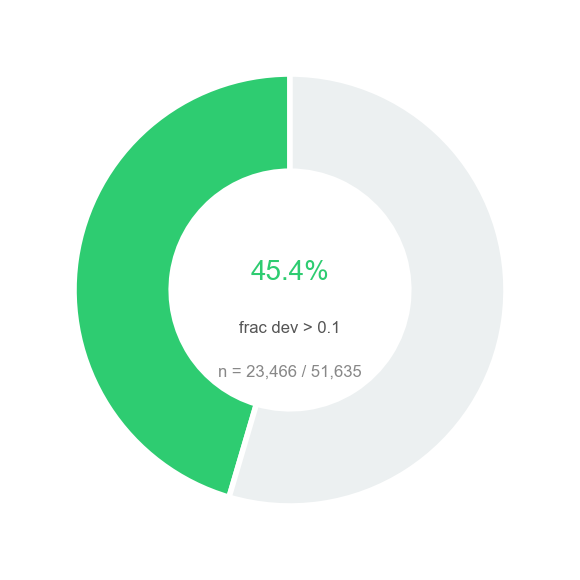

In [15]:
def plot_responsiveness_donut(df, threshold=0.05, figsize=(3, 3)):
    """
    Donut chart: % of neurons with test_frac_dev above threshold.
    """
    n_total = len(df)
    n_resp  = (df['test_frac_dev'] > threshold).sum()
    n_not   = n_total - n_resp
    pct     = n_resp / n_total * 100

    fig, ax = plt.subplots(figsize=figsize, dpi=200)
    wedges, _ = ax.pie(
        [n_resp, n_not],
        colors=['#2ECC71', '#ECF0F1'],
        startangle=90,
        wedgeprops=dict(width=0.45, edgecolor='white', linewidth=2),
    )
    # Centre text
    ax.text(0, 0.08, f'{pct:.1f}%',   ha='center', va='center',
            fontsize=10, color='#2ECC71')
    ax.text(0, -0.18, f'frac dev > {threshold}', ha='center', va='center',
            fontsize=6, color='#555555')
    ax.text(0, -0.38, f'n = {n_resp:,} / {n_total:,}', ha='center', va='center',
            fontsize=6, color='#888888')
    #ax.set_title('Neuron responsiveness', fontsize=10, pad=12)
    plt.tight_layout()
    plt.show()
    return fig

figure = plot_responsiveness_donut(df_neurons, threshold=0.1)

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_43525/1741347595.py:20: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap     = plt.cm.get_cmap('tab10', len(mice))


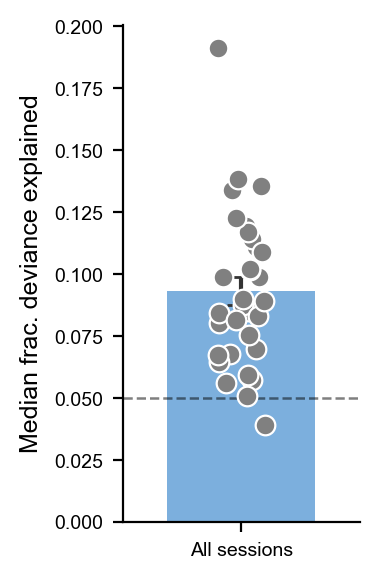

In [16]:
def plot_frac_dev_summary(df, threshold=0.05, figsize=(2, 3)):
    """
    Single bar showing mean frac_dev across all neurons,
    with one dot per session (session median) overlaid.
    Error bar = SEM across sessions.
    """
    # One value per session (median frac_dev)
    sess_medians = (
        df.groupby(['mouse_ID', 'date'])['test_frac_dev']
        .median()
        .reset_index()
    )
    sess_medians.columns = ['mouse_ID', 'date', 'median_fd']

    grand_mean = sess_medians['median_fd'].mean()
    grand_sem  = sess_medians['median_fd'].sem()

    # Colour dots by mouse
    mice     = sess_medians['mouse_ID'].unique()
    cmap     = plt.cm.get_cmap('tab10', len(mice))
    m_colors = {m: cmap(i) for i, m in enumerate(mice)}

    fig, ax = plt.subplots(figsize=figsize, dpi=200)

    # Bar
    ax.bar(0, grand_mean, yerr=grand_sem, width=0.5,
           color='#5B9BD5', alpha=0.8,
           error_kw=dict(elinewidth=1.5, capsize=5, ecolor='#333333'),
           zorder=2)

    # Session dots — jittered slightly so they don't overlap
    rng = np.random.default_rng(seed=0)
    jitter = rng.uniform(-0.08, 0.08, size=len(sess_medians))
    for i, row in sess_medians.iterrows():
        ax.scatter(jitter[i], row['median_fd'],
                   color='grey',
                   s=50, zorder=4, edgecolors='white', linewidths=0.8)

    if threshold is not None:
        ax.axhline(threshold, color='k', lw=0.9, ls='--', alpha=0.5,
                   label=f'threshold = {threshold}')

    # Legend for mice
    handles = [plt.Line2D([0], [0], marker='o', color='w',
                          markerfacecolor=m_colors[m], markersize=7)
               for m in mice]
    # ax.legend(handles, mice, fontsize=7, frameon=False,
    #           loc='upper right', title='Mouse', title_fontsize=7)

    ax.set_xticks([0])
    ax.set_xticklabels(['All sessions'])
    ax.set_xlim(-0.4, 0.4)
    ax.set_ylabel('Median frac. deviance explained', fontsize=9)
    #ax.set_title('Model fit summary\n(bar = mean ± SEM, dots = sessions)', fontsize=9)
    sns.despine()
    plt.tight_layout()
    plt.show()
    return fig

figure = plot_frac_dev_summary(df_neurons, threshold=0.05)

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_43525/1024508669.py:15: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap     = plt.cm.get_cmap('tab10', len(mice))


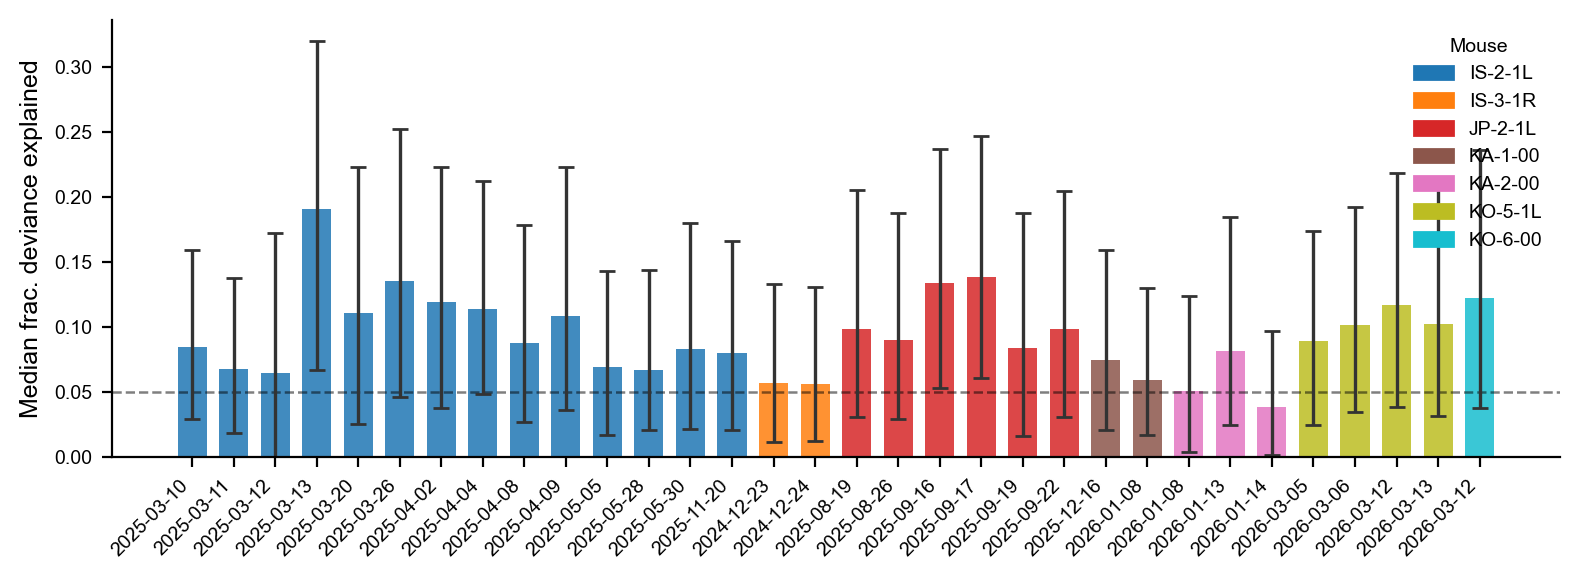

In [17]:
def plot_frac_dev_by_session(df, threshold=0.05, figsize=(8, 3)):
    """
    One bar per session showing median frac_dev,
    error bar = IQR (or SEM across neurons within session).
    Bars are coloured by mouse_ID.
    """
    sess_stats = (
        df.groupby(['mouse_ID', 'date'])['test_frac_dev']
        .agg(median='median', sem='sem', q25=lambda x: x.quantile(0.25),
             q75=lambda x: x.quantile(0.75))
        .reset_index()
    )

    mice     = sess_stats['mouse_ID'].unique()
    cmap     = plt.cm.get_cmap('tab10', len(mice))
    m_colors = {m: cmap(i) for i, m in enumerate(mice)}

    fig, ax = plt.subplots(figsize=figsize, dpi=200)

    for i, row in sess_stats.iterrows():
        color   = m_colors[row['mouse_ID']]
        err_low = row['median'] - row['q25']
        err_hi  = row['q75']   - row['median']
        ax.bar(i, row['median'],
               yerr=[[err_low], [err_hi]],
               color=color, alpha=0.85, width=0.7,
               error_kw=dict(elinewidth=1.2, capsize=3, ecolor='#333333'),
               zorder=2)

    if threshold is not None:
        ax.axhline(threshold, color='k', lw=0.9, ls='--', alpha=0.5,
                   label=f'threshold = {threshold}')

    # x-axis labels: date only (mouse colour encodes identity)
    ax.set_xticks(range(len(sess_stats)))
    ax.set_xticklabels(sess_stats['date'], rotation=45, ha='right', fontsize=7)
    ax.set_ylabel('Median frac. deviance explained', fontsize=9)

    # Mouse colour legend
    handles = [plt.Rectangle((0, 0), 1, 1, color=m_colors[m]) for m in mice]
    ax.legend(handles, mice, fontsize=7, frameon=False,
              loc='upper right', title='Mouse', title_fontsize=7)

    sns.despine()
    plt.tight_layout()
    plt.show()
    return fig

figure = plot_frac_dev_by_session(df_neurons, threshold=0.05)

/var/folders/tb/ct0s7r6j0q90l_p7cs6hshr80000gn/T/ipykernel_43525/3219539737.py:47: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap     = plt.cm.get_cmap('tab10', len(mice))


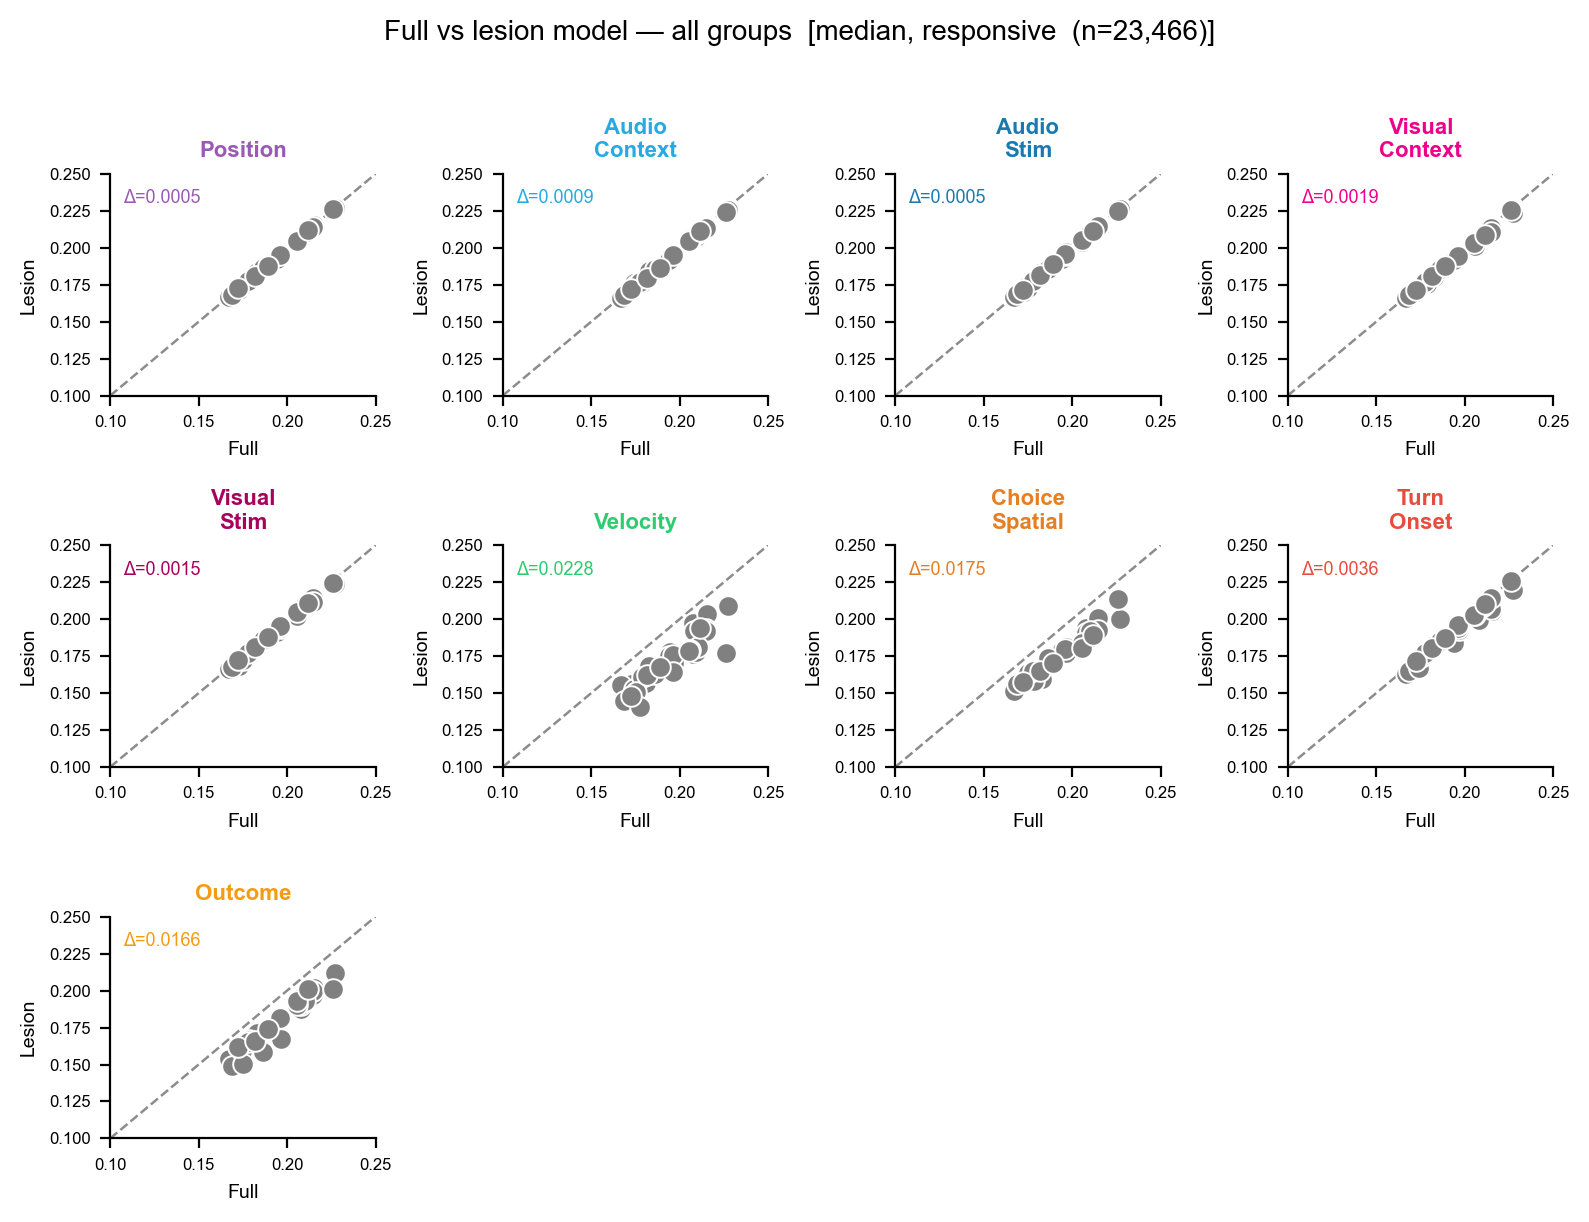

In [18]:
def plot_full_vs_lesion_all_groups(
    df,
    agg             = 'median',
    responsive_only = True,
    ncols           = 4,
    figsize         = None,
):
    """
    Grid of scatter plots: full model frac_dev vs lesion frac_dev,
    one panel per predictor group, one dot per session.

    Points above the unity line = that group contributes to model fit.
    The further above, the more important the group.

    Parameters
    ----------
    df              : DataFrame from build_neuron_dataframe
    agg             : 'median' or 'mean'  — per-session summary stat
    responsive_only : bool
    ncols           : int  — columns in the grid (default 4 leaves a spare panel for legend)
    figsize         : tuple or None (auto-sized)
    """
    data   = df[df['is_responsive']] if responsive_only else df
    agg_fn = 'median' if agg == 'median' else 'mean'

    groups = [g for g in GROUP_ORDER if f'delta_fd_{g}' in data.columns]
    nrows  = int(np.ceil((len(groups) + 1) / ncols))  # +1 reserves a panel for the legend

    if figsize is None:
        figsize = (ncols * 2, nrows * 2)

    # Pre-compute per-session stats for all groups at once
    sess_base = (
        data.groupby(['mouse_ID', 'date'])
        .agg(
            full_fd   = ('test_frac_dev', agg_fn),
            n_neurons = ('test_frac_dev', 'count'),
            **{f'delta_fd_{g}': (f'delta_fd_{g}', agg_fn) for g in groups}
        )
        .reset_index()
    )
    for g in groups:
        sess_base[f'lesion_fd_{g}'] = sess_base['full_fd'] - sess_base[f'delta_fd_{g}']

    # Colour by mouse
    mice     = sess_base['mouse_ID'].unique()
    cmap     = plt.cm.get_cmap('tab10', len(mice))
    m_colors = {m: cmap(i) for i, m in enumerate(mice)}

    fig, axes = plt.subplots(nrows, ncols, figsize=figsize, dpi=200)
    axes_flat = list(axes.flat)   # convert once — avoids generator exhaustion

    for ax in axes_flat:
        ax.set_visible(False)

    for idx, grp in enumerate(groups):
        ax = axes_flat[idx]
        ax.set_visible(True)

        x_col = 'full_fd'
        y_col = f'lesion_fd_{grp}'

        for _, row in sess_base.iterrows():
            ax.scatter(row[x_col], row[y_col],
                       color='grey',
                       s=55, zorder=4, edgecolors='white', linewidths=0.7,
                       label=row['mouse_ID'])

        # Unity line
        all_vals = pd.concat([sess_base[x_col], sess_base[y_col]])
        lo, hi   = 0.1, 0.25
        ax.plot([lo, hi], [lo, hi], 'k--', lw=0.9, alpha=0.45, zorder=1)
        ax.set_xlim(lo, hi)
        ax.set_ylim(lo, hi)

        # Mean shift annotation
        mean_shift = (sess_base[x_col] - sess_base[y_col]).mean()
        ax.text(0.05, 0.93, f'Δ={mean_shift:.4f}',
                transform=ax.transAxes, fontsize=6.5,
                color=GROUP_COLORS.get(grp, '#333333'), va='top')

        ax.set_title(GROUP_LABELS.get(grp, grp), fontsize=8,
                     color=GROUP_COLORS.get(grp, '#333333'), fontweight='bold')
        ax.set_xlabel(f'Full', fontsize=7)
        ax.set_ylabel(f'Lesion', fontsize=7)
        ax.tick_params(labelsize=6)
        sns.despine(ax=ax)

    # Legend in the next available panel
    # legend_idx = len(groups)
    # if legend_idx < len(axes_flat):
    #     legend_ax = axes_flat[legend_idx]
    #     legend_ax.set_visible(True)
    #     legend_ax.axis('off')
    #     handles = [plt.Line2D([0], [0], marker='o', color='w',
    #                            markerfacecolor=m_colors[m], markersize=9)
    #                for m in mice]
    #     legend_ax.legend(handles, mice, fontsize=8, frameon=False,
    #                      loc='center', title='Mouse', title_fontsize=8)

    label = f'responsive  (n={len(data):,})' if responsive_only else f'all  (n={len(data):,})'
    fig.suptitle(f'Full vs lesion model — all groups  [{agg}, {label}]',
                 fontsize=10, y=1.01)
    plt.tight_layout()
    plt.show()
    return fig, sess_base


fig, sess_all = plot_full_vs_lesion_all_groups(df_neurons)

In [19]:
def build_lesion_dataframe(df):
    """
    Extract a focused DataFrame with just the lesion delta columns per neuron.

    Columns
    -------
    Identity (from index + columns):
        neuron_uid  (index)
        mouse_ID, date, neuron_idx

    Model quality:
        test_frac_dev       — full model performance
        is_responsive

    Per-group deltas:
        delta_fd_{group}    — unique frac_dev contribution (full − lesion)
        delta_r2_{group}    — unique R² contribution

    Classification:
        dominant_group, dominant_delta
        runner_up_group, runner_up_delta
        mixedness, neuron_class
    """
    id_cols    = ['mouse_ID', 'date', 'neuron_idx',
                  'test_frac_dev', 'is_responsive']
    delta_fd   = [c for c in df.columns if c.startswith('delta_fd_')]
    delta_r2   = [c for c in df.columns if c.startswith('delta_r2_')]
    class_cols = ['dominant_group', 'dominant_delta',
                  'runner_up_group', 'runner_up_delta',
                  'mixedness', 'neuron_class']

    keep = id_cols + delta_fd + delta_r2 + class_cols
    keep = [c for c in keep if c in df.columns]   # guard against missing cols

    df_lesion = df[keep].copy()

    print(f'Lesion DataFrame: {df_lesion.shape[0]:,} neurons × {df_lesion.shape[1]} columns')
    print(f'  Groups: {[c.replace("delta_fd_","") for c in delta_fd]}')
    return df_lesion


df_lesion = build_lesion_dataframe(df_neurons)
df_lesion.head()

Lesion DataFrame: 51,635 neurons × 29 columns
  Groups: ['position_only', 'audio_context', 'audio_stim', 'visual_context', 'visual_stim', 'velocity', 'choice_spatial', 'turn_onset', 'outcome']


,mouse_ID,date,neuron_idx,test_frac_dev,is_responsive,delta_fd_position_only,delta_fd_audio_context,delta_fd_audio_stim,delta_fd_visual_context,delta_fd_visual_stim,...,delta_r2_velocity,delta_r2_choice_spatial,delta_r2_turn_onset,delta_r2_outcome,dominant_group,dominant_delta,runner_up_group,runner_up_delta,mixedness,neuron_class
neuron_uid,,,,,,,,,,,,,,,,,,,,,
IS-2-1L_2025-03-10_n0,IS-2-1L,2025-03-10,0,0.177405,True,0.002257,0.002787,0.002955,0.001456,0.002986,...,0.081106,0.013228,0.001668,0.092206,velocity,0.035986,outcome,0.022883,0.635900,mixed
IS-2-1L_2025-03-10_n1,IS-2-1L,2025-03-10,1,0.022238,False,0.000164,-0.000144,0.001720,0.001554,-0.000153,...,-0.022057,0.061423,-0.006044,0.037416,outcome,0.008243,velocity,0.002843,0.344919,unclassified
IS-2-1L_2025-03-10_n2,IS-2-1L,2025-03-10,2,0.042549,False,-0.001386,0.006036,-0.000906,-0.000340,0.005980,...,0.020434,0.000080,0.004847,0.017334,velocity,0.025312,outcome,0.012849,0.507635,unclassified
IS-2-1L_2025-03-10_n3,IS-2-1L,2025-03-10,3,0.192938,True,0.001456,0.000102,0.000865,-0.001949,0.000601,...,0.043749,0.011875,0.013188,0.072160,velocity,0.077809,outcome,0.019272,0.247685,velocity
IS-2-1L_2025-03-10_n4,IS-2-1L,2025-03-10,4,0.045501,False,0.004926,0.000465,0.001684,0.001221,0.001426,...,0.012680,0.014495,0.004440,0.008846,choice_spatial,0.006557,turn_onset,0.005560,0.848031,unclassified


In [20]:
# Neurons × groups delta matrix (responsive neurons only, clipped at 0)
delta_fd_cols = [f'delta_fd_{g}' for g in GROUP_ORDER if f'delta_fd_{g}' in df_neurons.columns]

df_delta_resp = (
    df_neurons
    .loc[df_neurons['is_responsive'], delta_fd_cols]
    .clip(lower=0)                                         # treat negative deltas as 0
    .rename(columns=lambda c: c.replace('delta_fd_', '')) # clean column names
)

# Numpy matrix version for numerical work
X_delta = np.abs(df_delta_resp.to_numpy())   # shape: (n_responsive_neurons, n_groups)

print(f'Matrix shape: {X_delta.shape}  — {X_delta.shape[0]:,} neurons × {X_delta.shape[1]} groups')
print(f'Columns: {df_delta_resp.columns.tolist()}')
df_delta_resp.head()

Matrix shape: (23466, 9)  — 23,466 neurons × 9 groups
Columns: ['position_only', 'audio_context', 'audio_stim', 'visual_context', 'visual_stim', 'velocity', 'choice_spatial', 'turn_onset', 'outcome']


,position_only,audio_context,audio_stim,visual_context,visual_stim,velocity,choice_spatial,turn_onset,outcome
neuron_uid,,,,,,,,,
IS-2-1L_2025-03-10_n0,0.002257,0.002787,0.002955,0.001456,0.002986,0.035986,0.007010,0.002798,0.022883
IS-2-1L_2025-03-10_n3,0.001456,0.000102,0.000865,0.000000,0.000601,0.077809,0.011299,0.012316,0.019272
IS-2-1L_2025-03-10_n6,0.002831,0.003179,0.003597,0.001182,0.003471,0.010696,0.016974,0.020644,0.033449
IS-2-1L_2025-03-10_n9,0.000939,0.002854,0.001130,0.000000,0.001786,0.122985,0.024602,0.000290,0.010037
IS-2-1L_2025-03-10_n10,0.000524,0.002076,0.002422,0.000838,0.000000,0.069615,0.006831,0.007265,0.010783


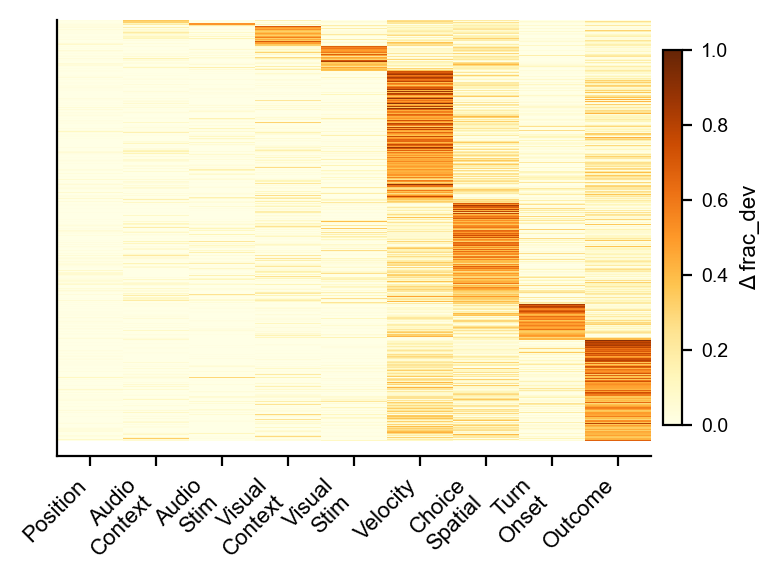

In [21]:
def plot_delta_heatmap(
    X_delta,
    df_meta,
    sort_by   = 'dominant_group',
    normalise = 'row',
    figsize   = (4, 3),
    cmap      = 'YlOrBr',
):
    """
    Heatmap: neurons (rows) × predictor groups (cols).

    Parameters
    ----------
    X_delta   : numpy array (n_neurons, n_groups) — from df_delta_resp.to_numpy()
    df_meta   : df_delta_resp (or df_neurons filtered to responsive) —
                must have columns: group names as columns, plus
                'dominant_group' and 'dominant_delta' in df_neurons
                (pass df_neurons.loc[df_delta_resp.index] for metadata)
    sort_by   : 'dominant_group' or a group name e.g. 'velocity'
    normalise : 'row' | 'none' | 'zscore'
    figsize   : tuple
    cmap      : str
    """
    groups = df_delta_resp.columns.tolist()   # group names from the matrix columns

    mat = np.clip(X_delta, 0, None).copy()

    # ── Sort rows ─────────────────────────────────────────────────────────
    meta = df_neurons.loc[df_delta_resp.index]   # aligned metadata

    if sort_by == 'dominant_group':
        group_rank = {g: i for i, g in enumerate(GROUP_ORDER + ['mixed', 'unclassified'])}
        sort_keys  = (
            meta['dominant_group'].map(group_rank).fillna(99).values * 1e6
            - meta['dominant_delta'].fillna(0).values
        )
        order = np.argsort(sort_keys)
    elif sort_by in groups:
        order = np.argsort(-mat[:, groups.index(sort_by)])
    else:
        raise ValueError(f'sort_by must be "dominant_group" or one of {groups}')

    mat      = mat[order]
    meta_ord = meta.iloc[order]

    # ── Normalise ─────────────────────────────────────────────────────────
    if normalise == 'row':
        row_sum = mat.sum(axis=1, keepdims=True)
        row_sum[row_sum == 0] = 1
        mat        = mat / row_sum
        cbar_label = 'Δ frac_dev'
        vmin, vmax = 0, 1
    elif normalise == 'zscore':
        from scipy.stats import zscore as _zscore
        mat        = np.nan_to_num(_zscore(mat, axis=1))
        cbar_label = 'Z-score across groups'
        vmin, vmax = -2, 2
    else:
        cbar_label = 'Δ frac. deviance'
        vmin, vmax = 0, np.percentile(mat, 99)

    # ── Plot ──────────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=figsize, dpi=200)

    im = ax.imshow(mat, aspect='auto', cmap=cmap,
                   interpolation='nearest', vmin=vmin, vmax=vmax)

    ax.set_xticks(range(len(groups)))
    ax.set_xticklabels([GROUP_LABELS.get(g, g) for g in groups],
                       rotation=45, ha='right', fontsize=8)
    ax.set_yticks([])
    #ax.set_ylabel(f'Neurons  (n={len(mat):,})', fontsize=9)

    cbar = plt.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
    cbar.set_label(cbar_label, fontsize=8)
    cbar.ax.tick_params(labelsize=7)

    # # ── Class boundary lines + labels in left margin ───────────────────────
    # if sort_by == 'dominant_group':
    #     classes = meta_ord['dominant_group'].values
    #     prev, start = classes[0], 0
    #     boundaries = []
    #     for i, cls in enumerate(classes):
    #         if cls != prev:
    #             boundaries.append((start, i, prev))
    #             prev, start = cls, i
    #     boundaries.append((start, len(classes), prev))

    #     for s, e, cls in boundaries:
    #         color = GROUP_COLORS.get(cls, '#aaaaaa')
    #         ax.add_patch(plt.Rectangle(
    #             (-0.5 - 0.35, s - 0.5), 0.35, e - s,
    #             color=color, clip_on=False, transform=ax.transData,
    #         ))
    #         ax.text(-0.5 - 0.65, (s + e) / 2,
    #                 GROUP_LABELS.get(cls, cls),
    #                 ha='right', va='center', fontsize=5.5,
    #                 color=color, transform=ax.transData)

    # ax.set_title(f'Δ frac_dev per group  |  sort={sort_by}  |  norm={normalise}\n'
    #              f'n={len(mat):,} responsive neurons', fontsize=8)
    plt.tight_layout()
    plt.show()
    return fig


figure = plot_delta_heatmap(X_delta, df_delta_resp)

In [25]:
# ── Step 1: build df_delta_resp (responsive neurons only) ─────────────────────
delta_cols = [f'delta_fd_{g}' for g in GROUP_ORDER]

RESP_THRESHOLD = 0.1
df_resp = df_neurons[df_neurons['test_frac_dev'] >= RESP_THRESHOLD].copy()

df_delta_resp = df_resp[delta_cols].copy()
df_delta_resp.columns = GROUP_ORDER
df_delta_resp = df_delta_resp.dropna()   # ← remove rows with any NaN

print(f'Responsive neurons: {len(df_delta_resp):,} / {len(df_neurons):,} '
      f'({len(df_delta_resp)/len(df_neurons)*100:.1f}%)')

# ── Step 2: build X_delta ─────────────────────────────────────────────────────
X_delta = df_delta_resp.to_numpy()

# ── Step 3: row-normalise → X_norm ────────────────────────────────────────────
X_clipped = np.clip(X_delta, 0, None)
row_sum   = X_clipped.sum(axis=1, keepdims=True)
row_sum[row_sum == 0] = 1
X_norm    = X_clipped / row_sum

print(f'X_norm shape: {X_norm.shape}')
print(f'NaNs in X_norm: {np.isnan(X_norm).sum()}')
print(f'Row sums (should all be ~1): min={X_norm.sum(axis=1).min():.3f}  '
      f'max={X_norm.sum(axis=1).max():.3f}')

Responsive neurons: 22,682 / 51,635 (43.9%)
X_norm shape: (22682, 9)
NaNs in X_norm: 0
Row sums (should all be ~1): min=1.000  max=1.000


Total groups (max possible dims): 9
PCs to explain 90% variance: 5
PCs to explain 95% variance: 5
PCs to explain 99% variance: 7


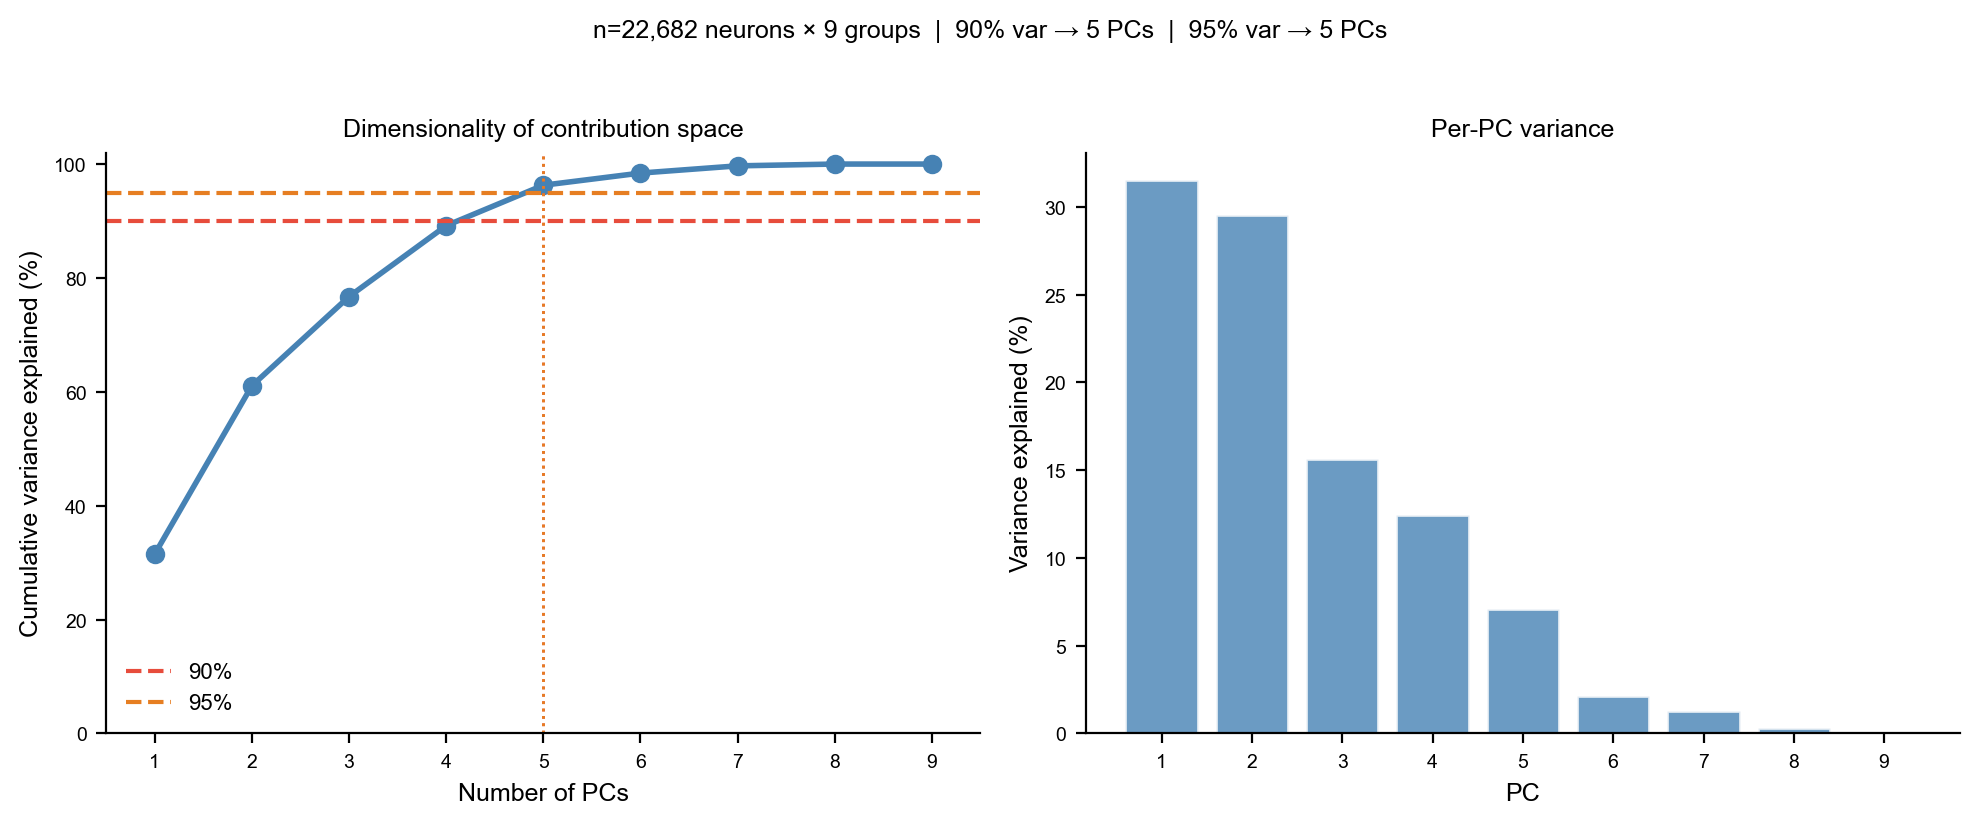

In [26]:
from sklearn.decomposition import PCA

# ── Fit PCA on the row-normalised contribution matrix ─────────────────────────
pca        = PCA()
pca.fit(X_norm)

cumvar     = np.cumsum(pca.explained_variance_ratio_)
n_dims_90  = np.searchsorted(cumvar, 0.90) + 1
n_dims_95  = np.searchsorted(cumvar, 0.95) + 1
n_dims_99  = np.searchsorted(cumvar, 0.99) + 1
n_groups   = X_norm.shape[1]

print(f'Total groups (max possible dims): {n_groups}')
print(f'PCs to explain 90% variance: {n_dims_90}')
print(f'PCs to explain 95% variance: {n_dims_95}')
print(f'PCs to explain 99% variance: {n_dims_99}')

# ── Plot ──────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(10, 4), dpi=200)

# Left: cumulative explained variance (scree)
ax = axes[0]
ax.plot(range(1, n_groups + 1), cumvar * 100, 'o-',
        color='steelblue', lw=2, markersize=6)
ax.axhline(90, color='#E74C3C', lw=1.5, ls='--', label='90%')
ax.axhline(95, color='#E67E22', lw=1.5, ls='--', label='95%')
ax.axvline(n_dims_90, color='#E74C3C', lw=1, ls=':')
ax.axvline(n_dims_95, color='#E67E22', lw=1, ls=':')
ax.set_xlabel('Number of PCs', fontsize=9)
ax.set_ylabel('Cumulative variance explained (%)', fontsize=9)
ax.set_title('Dimensionality of contribution space', fontsize=9)
ax.set_xlim(0.5, n_groups + 0.5)
ax.set_ylim(0, 102)
ax.legend(fontsize=8, frameon=False)
sns.despine(ax=ax)

# Right: individual PC variance (bar)
ax = axes[1]
ax.bar(range(1, n_groups + 1),
       pca.explained_variance_ratio_ * 100,
       color='steelblue', alpha=0.8, edgecolor='white')
ax.set_xlabel('PC', fontsize=9)
ax.set_ylabel('Variance explained (%)', fontsize=9)
ax.set_title('Per-PC variance', fontsize=9)
ax.set_xticks(range(1, n_groups + 1))
sns.despine(ax=ax)

plt.suptitle(
    f'n={X_norm.shape[0]:,} neurons × {n_groups} groups  |  '
    f'90% var → {n_dims_90} PCs  |  95% var → {n_dims_95} PCs',
    fontsize=9, y=1.02
)
plt.tight_layout()
plt.show()

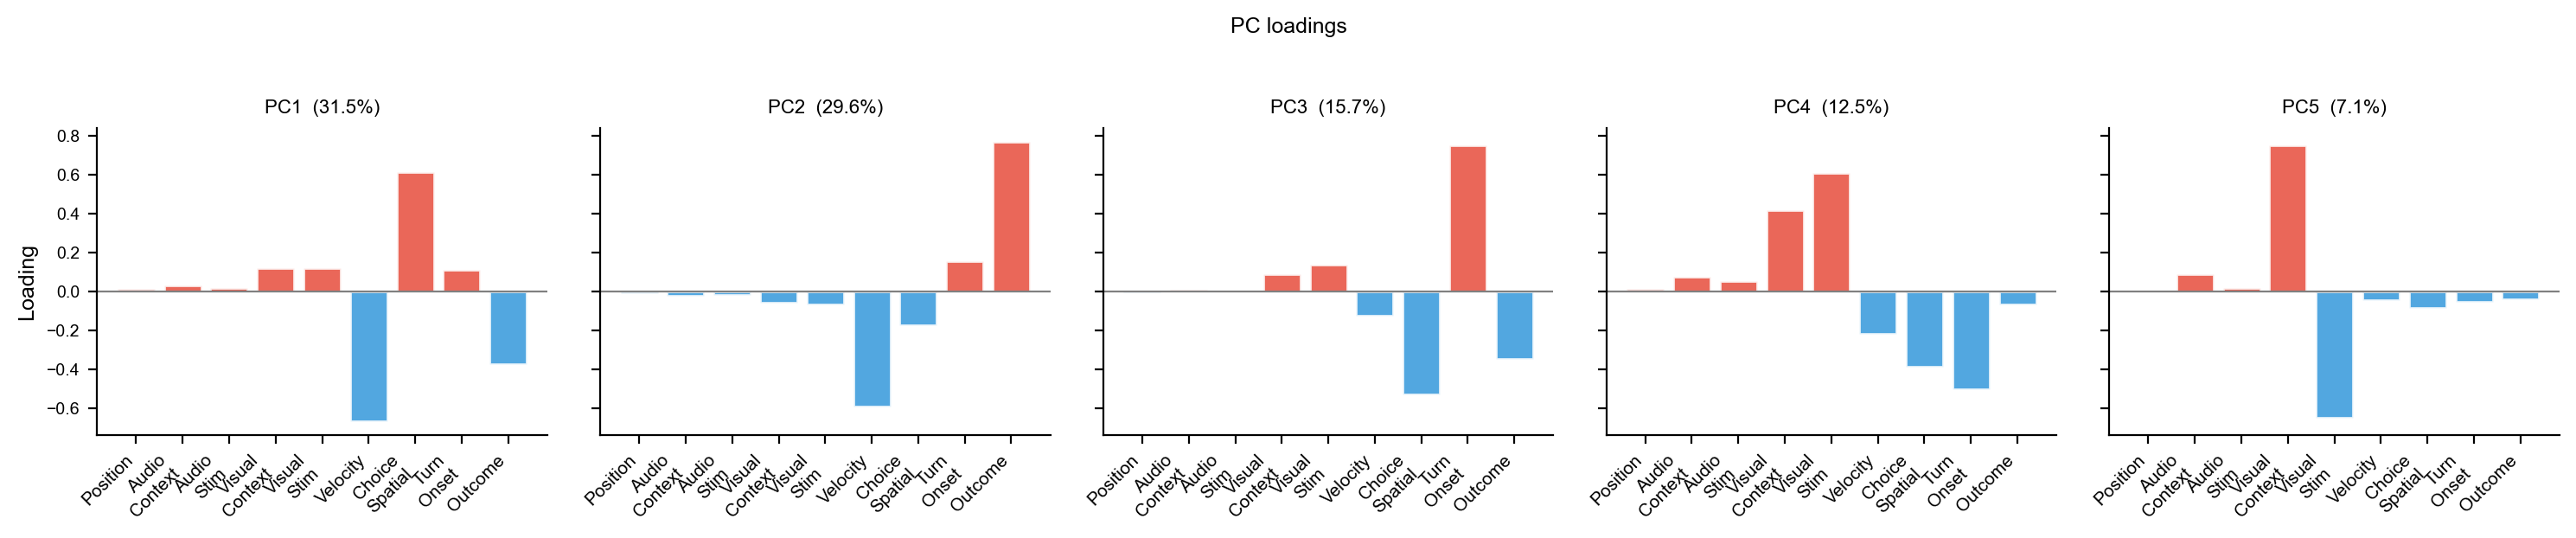

In [28]:
groups = df_delta_resp.columns.tolist()   # ← add this line before the loop

fig, axes = plt.subplots(1, n_dims_90, figsize=(3 * n_dims_90, 3), dpi=200, sharey=True)
if n_dims_90 == 1:
    axes = [axes]

for i, ax in enumerate(axes):
    loadings = pca.components_[i]
    colors   = ['#E74C3C' if v > 0 else '#3498DB' for v in loadings]
    ax.bar(range(len(groups)), loadings, color=colors, edgecolor='white', alpha=0.85)
    ax.axhline(0, color='gray', lw=0.8)
    ax.set_xticks(range(len(groups)))
    ax.set_xticklabels([GROUP_LABELS.get(g, g) for g in groups],
                       rotation=45, ha='right', fontsize=7.5)
    ax.set_title(f'PC{i+1}  ({pca.explained_variance_ratio_[i]*100:.1f}%)', fontsize=8)
    if i == 0:
        ax.set_ylabel('Loading', fontsize=9)
    sns.despine(ax=ax)

plt.suptitle('PC loadings', fontsize=9, y=1.02)
plt.tight_layout()
plt.show()

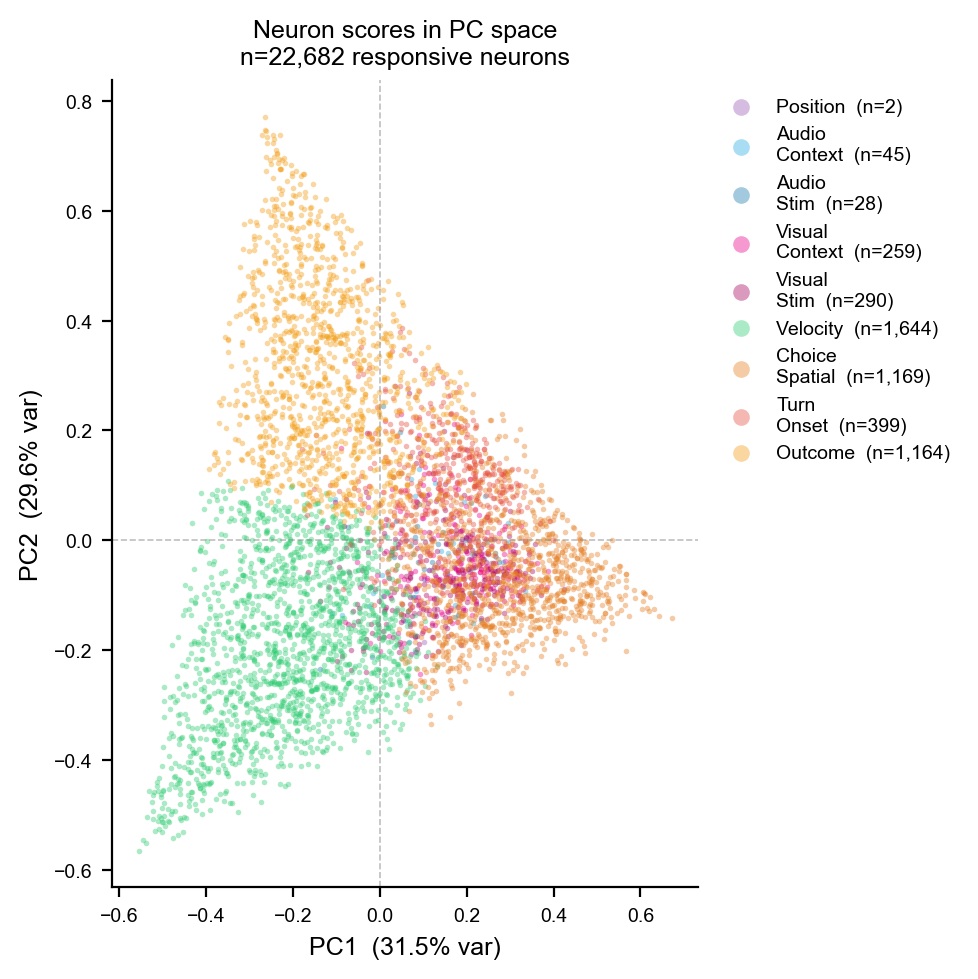

In [29]:
def plot_pc_scatter(X_norm, df_neurons, df_delta_resp, pca, groups,
                    pc_x=0, pc_y=1, figsize=(5, 5), n_sample=5000):
    """
    Scatter of neuron PC scores, coloured by dominant predictor group.
    pc_x, pc_y: 0-indexed PC axes to plot (default PC1 vs PC2)
    """
    scores = pca.transform(X_norm)   # (n_neurons, 9)

    meta = df_neurons.loc[df_delta_resp.index, 'dominant_group'].copy()

    # Subsample for speed/clarity
    rng  = np.random.default_rng(seed=0)
    samp = rng.choice(len(scores), size=min(n_sample, len(scores)), replace=False)

    fig, ax = plt.subplots(figsize=figsize, dpi=200)

    # Plot each group separately so legend works
    for grp in GROUP_ORDER + ['mixed', 'unclassified']:
        mask = (meta == grp).values
        mask_samp = mask[samp]
        if mask_samp.sum() == 0:
            continue
        color = GROUP_COLORS.get(grp, '#AAAAAA')
        label = GROUP_LABELS.get(grp, grp)
        ax.scatter(
            scores[samp][mask_samp, pc_x],
            scores[samp][mask_samp, pc_y],
            s=4, alpha=0.4, color=color, label=f'{label}  (n={mask_samp.sum():,})',
            rasterized=True, linewidths=0,
        )

    ax.axhline(0, color='gray', lw=0.6, ls='--', alpha=0.5)
    ax.axvline(0, color='gray', lw=0.6, ls='--', alpha=0.5)

    var_x = pca.explained_variance_ratio_[pc_x] * 100
    var_y = pca.explained_variance_ratio_[pc_y] * 100
    ax.set_xlabel(f'PC{pc_x + 1}  ({var_x:.1f}% var)', fontsize=9)
    ax.set_ylabel(f'PC{pc_y + 1}  ({var_y:.1f}% var)', fontsize=9)
    ax.set_title(f'Neuron scores in PC space\n'
                 f'n={len(scores):,} responsive neurons', fontsize=9)

    ax.legend(fontsize=7, frameon=False, markerscale=3,
              bbox_to_anchor=(1.01, 1), loc='upper left')
    sns.despine()
    plt.tight_layout()
    plt.show()
    return fig, scores


fig, scores = plot_pc_scatter(X_norm, df_neurons, df_delta_resp, pca, groups)

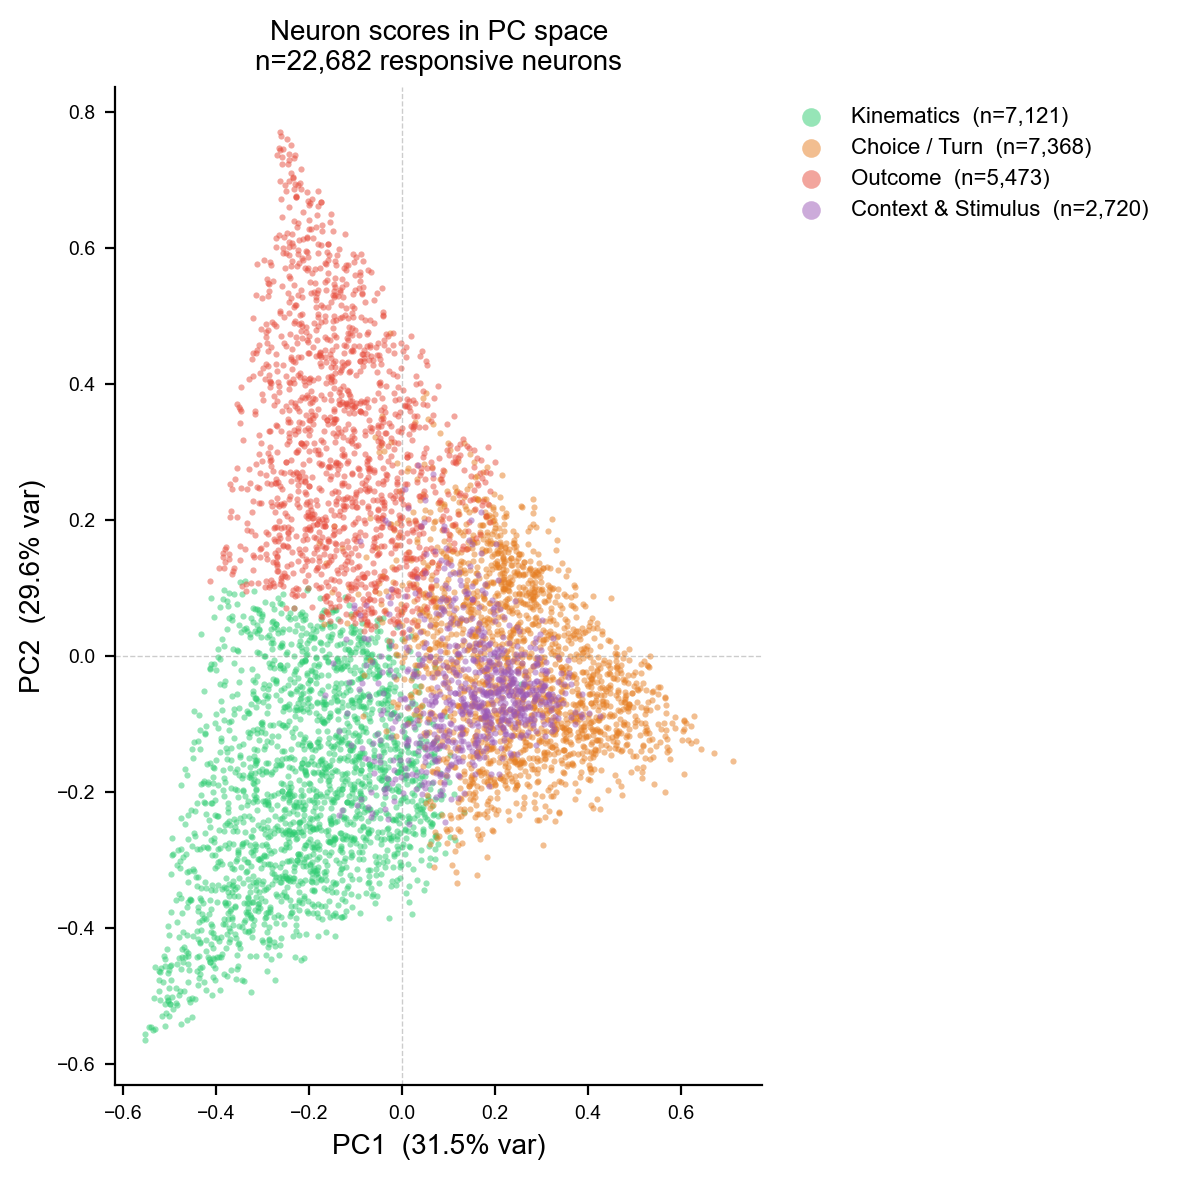

In [30]:
# ── Define the 4 broad functional clouds ──────────────────────────────────────
CLOUD_MAP = {
    'position_only':  'kinematics',
    'velocity':       'kinematics',
    'choice_spatial': 'choice',
    'turn_onset':     'choice',
    'outcome':        'outcome',
    'audio_context':  'context_stim',
    'audio_stim':     'context_stim',
    'visual_context': 'context_stim',
    'visual_stim':    'context_stim',
}

CLOUD_LABELS = {
    'kinematics':   'Kinematics',
    'choice':       'Choice / Turn',
    'outcome':      'Outcome',
    'context_stim': 'Context & Stimulus',
}

CLOUD_COLORS = {
    'kinematics':   '#2ECC71',   # green
    'choice':       '#E67E22',   # orange
    'outcome':      '#E74C3C',   # red
    'context_stim': '#9B59B6',   # purple
}

# ── Map each neuron's dominant_group → cloud ───────────────────────────────────
meta = df_neurons.loc[df_delta_resp.index, 'dominant_group'].copy()
cloud_labels_per_neuron = meta.map(CLOUD_MAP).fillna('mixed')

# ── Scores ────────────────────────────────────────────────────────────────────
scores = pca.transform(X_norm)

rng  = np.random.default_rng(seed=0)
samp = rng.choice(len(scores), size=min(6000, len(scores)), replace=False)

fig, ax = plt.subplots(figsize=(6, 6), dpi=200)

# Plot mixed/unclassified as light gray underneath
other_mask = ~cloud_labels_per_neuron.isin(CLOUD_MAP.values())
if other_mask.values[samp].any():
    ax.scatter(
        scores[samp][other_mask.values[samp], 0],
        scores[samp][other_mask.values[samp], 1],
        s=3, alpha=0.15, color='#CCCCCC',
        rasterized=True, linewidths=0, label='Mixed / unclassified',
    )

# Plot the 4 clouds
for cloud in ['kinematics', 'choice', 'outcome', 'context_stim']:
    mask      = (cloud_labels_per_neuron == cloud).values
    mask_samp = mask[samp]
    n_total   = mask.sum()
    if mask_samp.sum() == 0:
        continue
    ax.scatter(
        scores[samp][mask_samp, 0],
        scores[samp][mask_samp, 1],
        s=5, alpha=0.5,
        color=CLOUD_COLORS[cloud],
        label=f'{CLOUD_LABELS[cloud]}  (n={n_total:,})',
        rasterized=True, linewidths=0,
    )

ax.axhline(0, color='gray', lw=0.5, ls='--', alpha=0.4)
ax.axvline(0, color='gray', lw=0.5, ls='--', alpha=0.4)

var_x = pca.explained_variance_ratio_[0] * 100
var_y = pca.explained_variance_ratio_[1] * 100
ax.set_xlabel(f'PC1  ({var_x:.1f}% var)', fontsize=10)
ax.set_ylabel(f'PC2  ({var_y:.1f}% var)', fontsize=10)
ax.set_title(f'Neuron scores in PC space\nn={len(scores):,} responsive neurons', fontsize=10)

ax.legend(fontsize=8, frameon=False, markerscale=3,
          bbox_to_anchor=(1.01, 1), loc='upper left')
sns.despine()
plt.tight_layout()
plt.show()

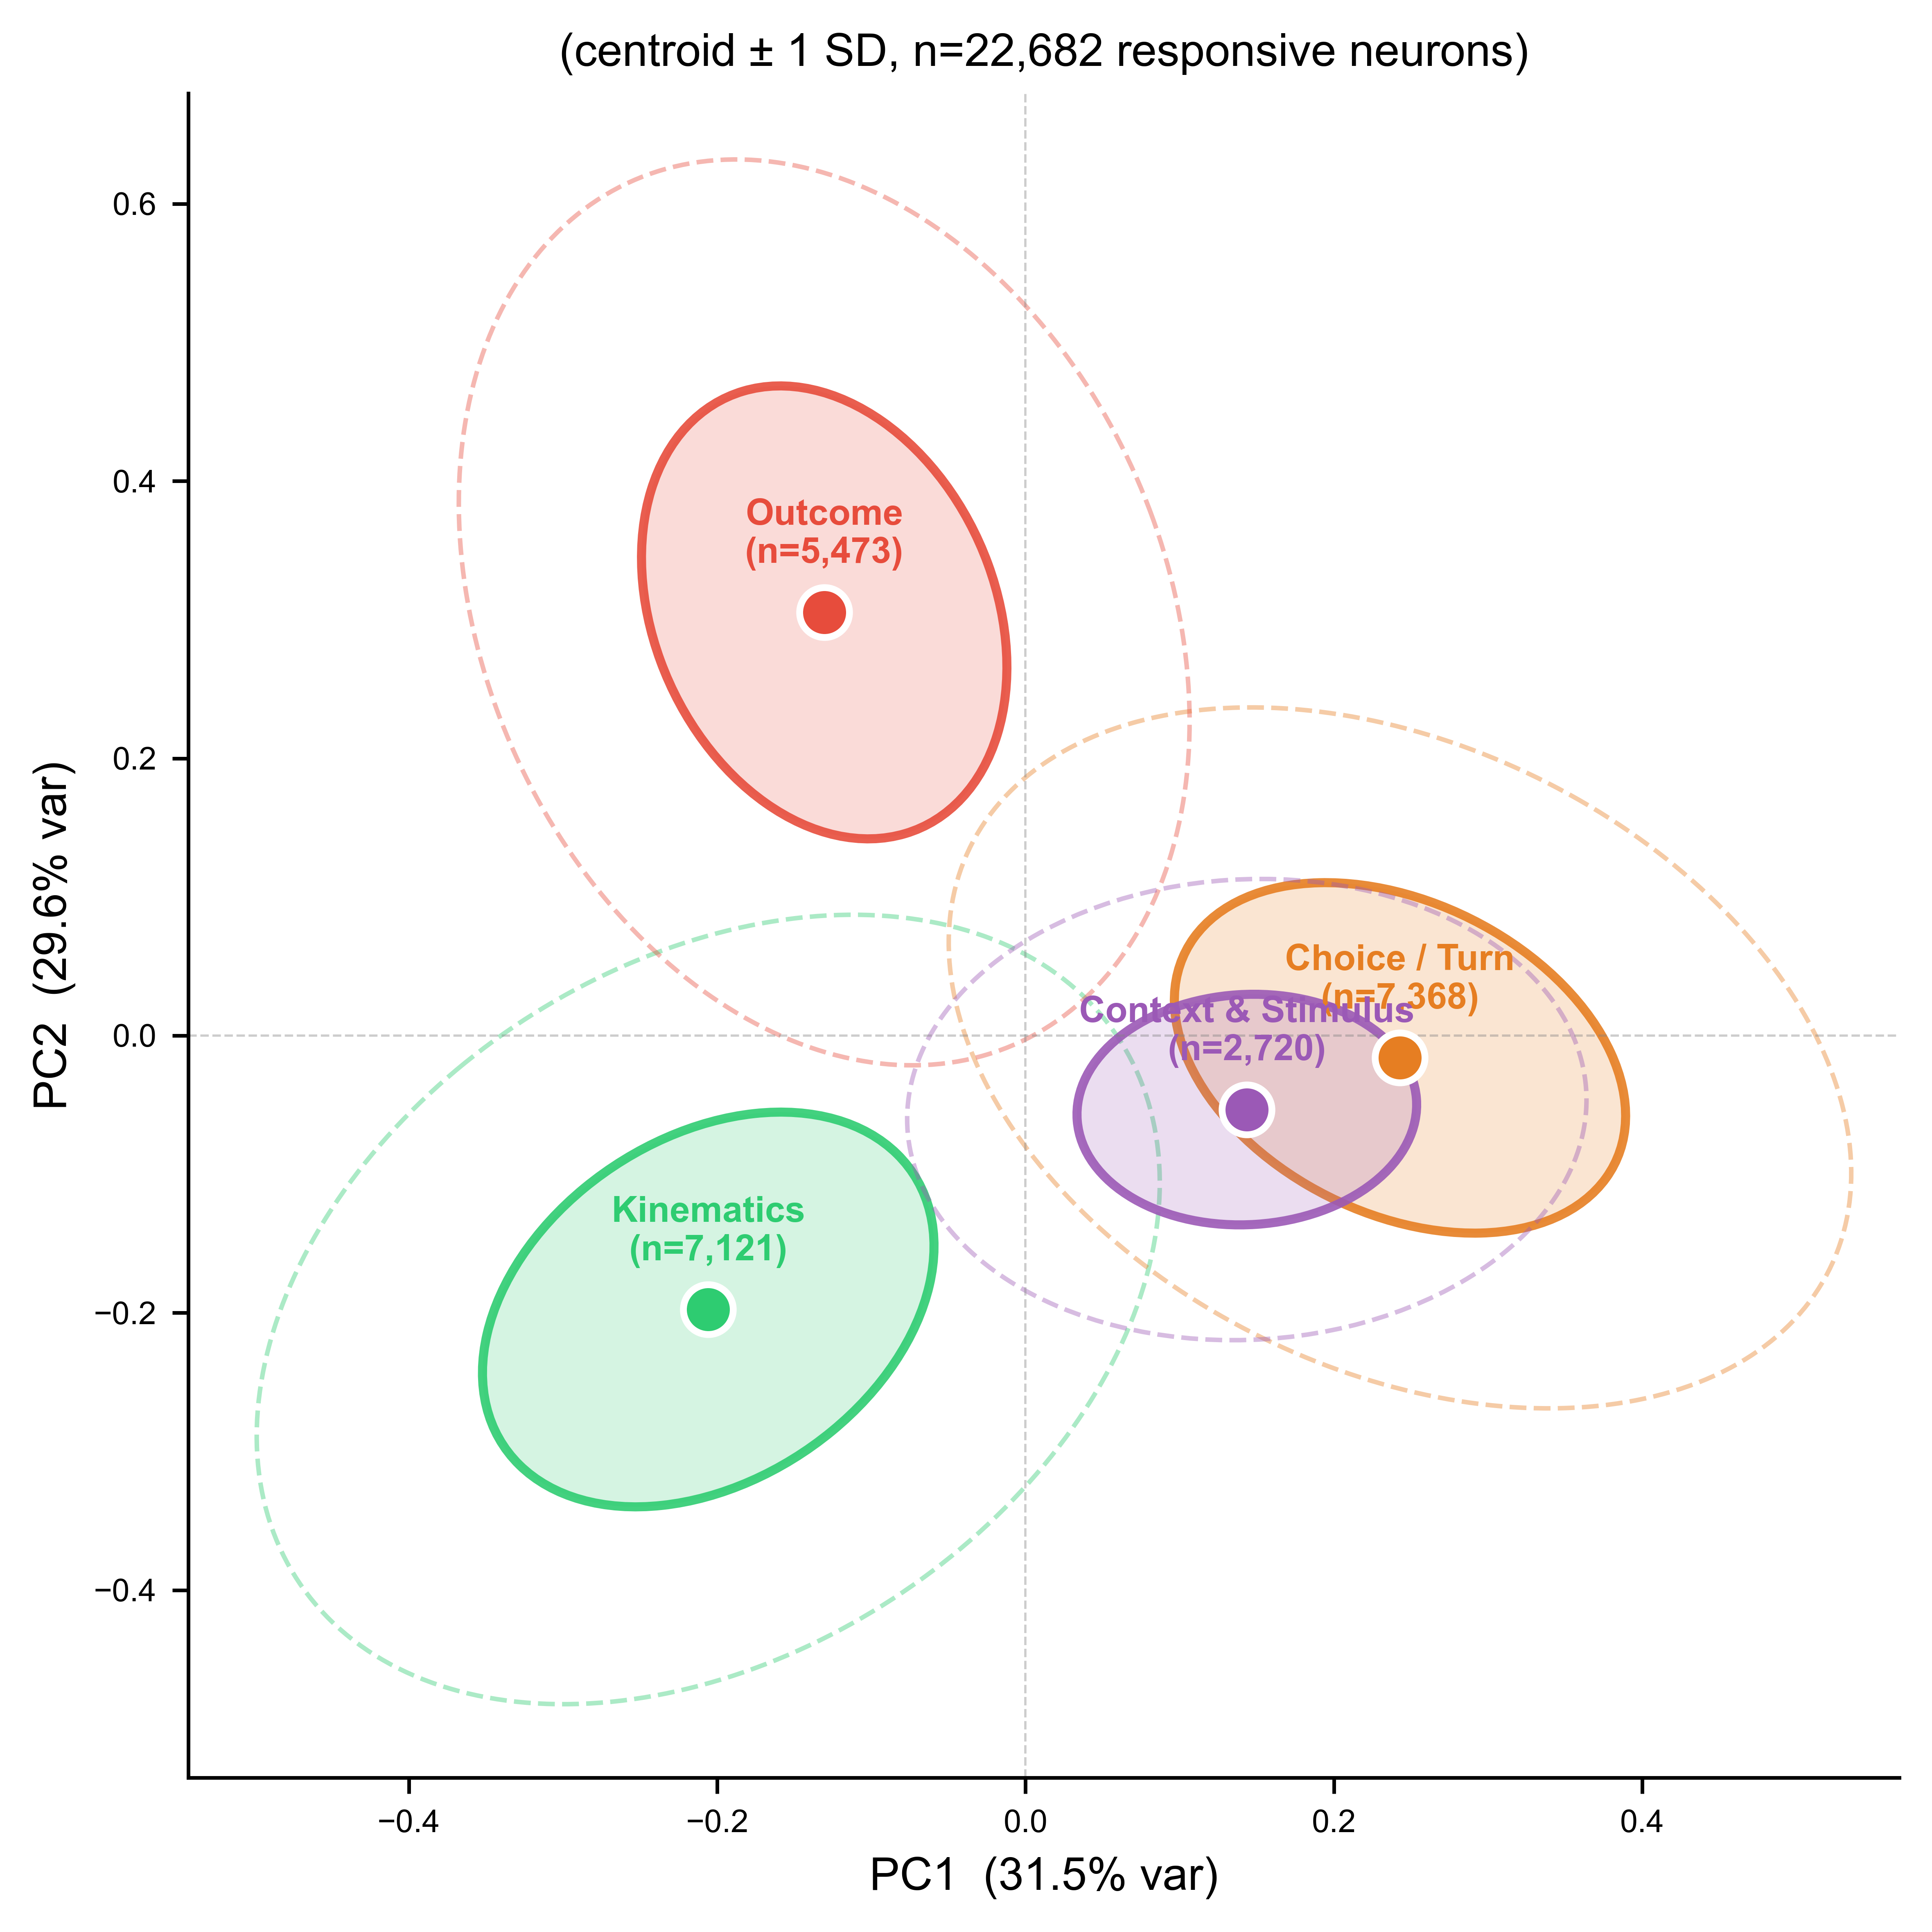

In [31]:
from matplotlib.patches import Ellipse
import matplotlib.transforms as transforms

def confidence_ellipse(x, y, ax, n_std=1.0, **kwargs):
    """Draw a covariance confidence ellipse for (x, y) data."""
    cov  = np.cov(x, y)
    mean_x, mean_y = np.mean(x), np.mean(y)

    # Eigendecomposition for ellipse shape
    vals, vecs = np.linalg.eigh(cov)
    order      = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]
    theta      = np.degrees(np.arctan2(*vecs[:, 0][::-1]))
    w, h       = 2 * n_std * np.sqrt(vals)

    ellipse = Ellipse(
        xy=(mean_x, mean_y), width=w, height=h, angle=theta,
        **kwargs
    )
    ax.add_patch(ellipse)
    return mean_x, mean_y


fig, ax = plt.subplots(figsize=(6, 6), dpi=800)

for cloud in ['kinematics', 'choice', 'outcome', 'context_stim']:
    mask  = (cloud_labels_per_neuron == cloud).values
    if mask.sum() < 10:
        continue
    x = scores[mask, 0]
    y = scores[mask, 1]
    color = CLOUD_COLORS[cloud]
    label = CLOUD_LABELS[cloud]
    n     = mask.sum()

    # 1 SD filled ellipse (lighter)
    confidence_ellipse(x, y, ax, n_std=1.0,
                       facecolor=color, alpha=0.2, edgecolor='none')
    # 1 SD ellipse outline
    confidence_ellipse(x, y, ax, n_std=1.0,
                       facecolor='none', edgecolor=color, lw=2, alpha=0.9)
    # 2 SD dashed outline
    confidence_ellipse(x, y, ax, n_std=2.0,
                       facecolor='none', edgecolor=color, lw=1,
                       alpha=0.4, linestyle='--')

    # Centroid dot
    cx, cy = np.mean(x), np.mean(y)
    ax.scatter(cx, cy, color=color, s=120, zorder=5,
               edgecolors='white', linewidths=1.5)

    # Label at centroid
    ax.text(cx, cy + 0.03, f'{label}\n(n={n:,})',
            ha='center', va='bottom', fontsize=8,
            color=color, fontweight='bold')

ax.axhline(0, color='gray', lw=0.5, ls='--', alpha=0.4)
ax.axvline(0, color='gray', lw=0.5, ls='--', alpha=0.4)

var_x = pca.explained_variance_ratio_[0] * 100
var_y = pca.explained_variance_ratio_[1] * 100
ax.set_xlabel(f'PC1  ({var_x:.1f}% var)', fontsize=10)
ax.set_ylabel(f'PC2  ({var_y:.1f}% var)', fontsize=10)
ax.set_title(f'(centroid ± 1 SD, n={len(scores):,} responsive neurons)',
             fontsize=10)

# Manual legend
handles = [plt.Line2D([0], [0], marker='o', color='w',
                       markerfacecolor=CLOUD_COLORS[c], markersize=9,
                       label=f'{CLOUD_LABELS[c]}  (n={((cloud_labels_per_neuron==c).sum()):,})')
           for c in ['kinematics', 'choice', 'outcome', 'context_stim']]
# ax.legend(handles=handles, fontsize=8, frameon=False,
#           bbox_to_anchor=(1.01, 1), loc='upper left')

sns.despine()
plt.tight_layout()
plt.show()

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), dpi=800)

pc_pairs = [(0, 2), (0, 3), (0, 4)]

for ax, (px, py) in zip(axes, pc_pairs):
    for cloud in ['kinematics', 'choice', 'outcome', 'context_stim']:
        mask = (cloud_labels_per_neuron == cloud).values
        if mask.sum() < 10:
            continue
        x     = scores[mask, px]
        y     = scores[mask, py]
        color = CLOUD_COLORS[cloud]
        label = CLOUD_LABELS[cloud]
        n     = mask.sum()

        # Filled 1 SD ellipse
        confidence_ellipse(x, y, ax, n_std=1.0,
                           facecolor=color, alpha=0.2, edgecolor='none')
        # 1 SD outline
        confidence_ellipse(x, y, ax, n_std=1.0,
                           facecolor='none', edgecolor=color, lw=2, alpha=0.9)
        # 2 SD dashed outline
        confidence_ellipse(x, y, ax, n_std=2.0,
                           facecolor='none', edgecolor=color, lw=1,
                           alpha=0.35, linestyle='--')
        # Centroid
        cx, cy = np.mean(x), np.mean(y)
        ax.scatter(cx, cy, color=color, s=100, zorder=5,
                   edgecolors='white', linewidths=1.5)
        ax.text(cx, cy + 0.025, f'{label}',
                ha='center', va='bottom', fontsize=7.5,
                color=color, fontweight='bold')

    ax.axhline(0, color='gray', lw=0.5, ls='--', alpha=0.4)
    ax.axvline(0, color='gray', lw=0.5, ls='--', alpha=0.4)

    vx = pca.explained_variance_ratio_[px] * 100
    vy = pca.explained_variance_ratio_[py] * 100
    ax.set_xlabel(f'PC{px+1}  ({vx:.1f}% var)', fontsize=9)
    ax.set_ylabel(f'PC{py+1}  ({vy:.1f}% var)', fontsize=9)
    ax.set_title(f'PC{px+1} vs PC{py+1}', fontsize=9)
    sns.despine(ax=ax)

# Single shared legend on the right
handles = [
    plt.Line2D([0], [0], marker='o', color='w',
               markerfacecolor=CLOUD_COLORS[c], markersize=9,
               label=f'{CLOUD_LABELS[c]}  (n={(cloud_labels_per_neuron==c).sum():,})')
    for c in ['kinematics', 'choice', 'outcome', 'context_stim']
]

plt.tight_layout()
plt.show()

In [33]:
# Centroid of each cloud in PC score space (use all PCs, not just 2)
cloud_centroids = {}
for cloud in ['kinematics', 'choice', 'outcome', 'context_stim']:
    mask = (cloud_labels_per_neuron == cloud).values
    cloud_centroids[cloud] = scores[mask].mean(axis=0)

# Pairwise cosine similarity between centroids
from itertools import combinations

print('Cosine similarity between group centroids (0=orthogonal, 1=parallel):')
print('(angle in degrees also shown)\n')
for a, b in combinations(cloud_centroids.keys(), 2):
    va = cloud_centroids[a]
    vb = cloud_centroids[b]
    cos_sim = np.dot(va, vb) / (np.linalg.norm(va) * np.linalg.norm(vb))
    angle   = np.degrees(np.arccos(np.clip(cos_sim, -1, 1)))
    print(f'  {a:20s} vs {b:20s}:  cos={cos_sim:+.3f}  angle={angle:.1f}°')

Cosine similarity between group centroids (0=orthogonal, 1=parallel):
(angle in degrees also shown)

  kinematics           vs choice              :  cos=-0.598  angle=126.7°
  kinematics           vs outcome             :  cos=-0.341  angle=109.9°
  kinematics           vs context_stim        :  cos=-0.268  angle=105.6°
  choice               vs outcome             :  cos=-0.435  angle=115.8°
  choice               vs context_stim        :  cos=+0.111  angle=83.7°
  outcome              vs context_stim        :  cos=-0.339  angle=109.8°


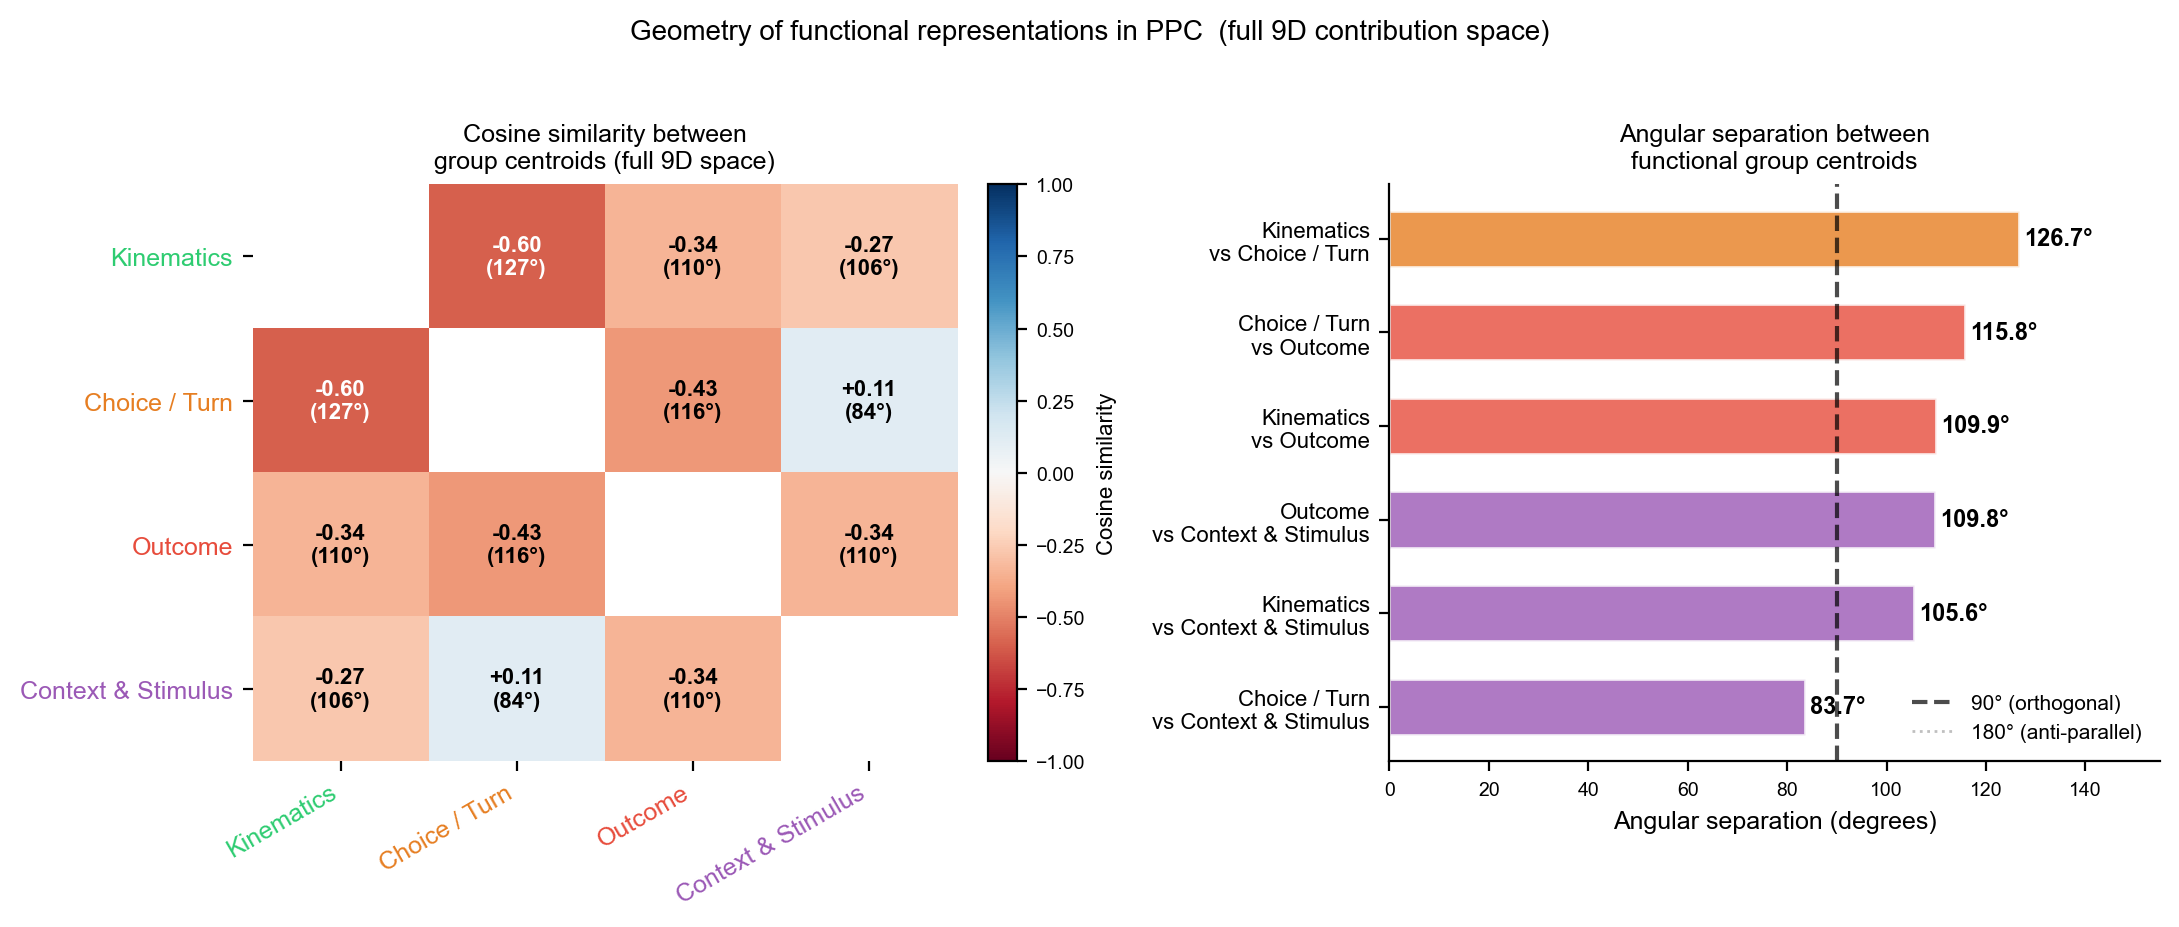

In [36]:
from itertools import combinations

clouds      = ['kinematics', 'choice', 'outcome', 'context_stim']
cloud_names = [CLOUD_LABELS[c] for c in clouds]
n_clouds    = len(clouds)

# ── Build cosine similarity matrix ────────────────────────────────────────────
cos_matrix   = np.zeros((n_clouds, n_clouds))
angle_matrix = np.zeros((n_clouds, n_clouds))

for i, a in enumerate(clouds):
    for j, b in enumerate(clouds):
        va      = cloud_centroids[a]
        vb      = cloud_centroids[b]
        cos_sim = np.dot(va, vb) / (np.linalg.norm(va) * np.linalg.norm(vb))
        cos_matrix[i, j]   = cos_sim
        angle_matrix[i, j] = np.degrees(np.arccos(np.clip(cos_sim, -1, 1)))

np.fill_diagonal(angle_matrix, np.nan)   # hide diagonal
np.fill_diagonal(cos_matrix,   np.nan)

# ── Figure ────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), dpi=200)

# ── Left: cosine similarity heatmap ───────────────────────────────────────────
ax = axes[0]
im = ax.imshow(cos_matrix, cmap='RdBu', vmin=-1, vmax=1,
               aspect='auto', interpolation='nearest')

for i in range(n_clouds):
    for j in range(n_clouds):
        if i != j:
            val   = cos_matrix[i, j]
            angle = angle_matrix[i, j]
            color = 'white' if abs(val) > 0.5 else 'black'
            ax.text(j, i, f'{val:+.2f}\n({angle:.0f}°)',
                    ha='center', va='center', fontsize=8,
                    color=color, fontweight='bold')

ax.set_xticks(range(n_clouds))
ax.set_yticks(range(n_clouds))
ax.set_xticklabels(cloud_names, rotation=30, ha='right', fontsize=9)
ax.set_yticklabels(cloud_names, fontsize=9)
ax.set_title('Cosine similarity between\ngroup centroids (full 9D space)', fontsize=9)

cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label('Cosine similarity', fontsize=8)
cbar.ax.tick_params(labelsize=7)

# Colour the tick labels by group
for tick, cloud in zip(ax.get_xticklabels(), clouds):
    tick.set_color(CLOUD_COLORS[cloud])
for tick, cloud in zip(ax.get_yticklabels(), clouds):
    tick.set_color(CLOUD_COLORS[cloud])

sns.despine(ax=ax, left=True, bottom=True)

# ── Right: angular separation bar chart ───────────────────────────────────────
ax = axes[1]

pair_labels = []
pair_angles = []
pair_colors = []

pair_order  = [
    ('choice', 'context_stim'),
    ('kinematics', 'context_stim'),
    ('outcome', 'context_stim'),
    ('kinematics', 'outcome'),
    ('choice', 'outcome'),
    ('kinematics', 'choice'),
]

for a, b in pair_order:
    va      = cloud_centroids[a]
    vb      = cloud_centroids[b]
    cos_sim = np.dot(va, vb) / (np.linalg.norm(va) * np.linalg.norm(vb))
    angle   = np.degrees(np.arccos(np.clip(cos_sim, -1, 1)))
    label   = f'{CLOUD_LABELS[a]}\nvs {CLOUD_LABELS[b]}'
    pair_labels.append(label)
    pair_angles.append(angle)
    # colour by the more "interesting" group in the pair
    pair_colors.append(CLOUD_COLORS[b])

bars = ax.barh(range(len(pair_labels)), pair_angles,
               color=pair_colors, alpha=0.8, edgecolor='white', height=0.6)

# Reference lines
ax.axvline(90,  color='black',  lw=1.5, ls='--', alpha=0.7, label='90° (orthogonal)')
ax.axvline(180, color='gray',   lw=1,   ls=':',  alpha=0.5, label='180° (anti-parallel)')

# Annotate each bar with angle value
for i, (bar, angle) in enumerate(zip(bars, pair_angles)):
    ax.text(angle + 1, i, f'{angle:.1f}°',
            va='center', fontsize=8.5, fontweight='bold',
            color='black')

ax.set_yticks(range(len(pair_labels)))
ax.set_yticklabels(pair_labels, fontsize=8)
ax.set_xlabel('Angular separation (degrees)', fontsize=9)
ax.set_xlim(0, 155)
ax.set_title('Angular separation between\nfunctional group centroids', fontsize=9)
ax.legend(fontsize=7.5, frameon=False, loc='lower right')
sns.despine(ax=ax)

plt.suptitle('Geometry of functional representations in PPC  (full 9D contribution space)',
             fontsize=10, y=1.02)
plt.tight_layout()
plt.show()

In [35]:
from scipy.stats import percentileofscore

# ── One-sided p-values ────────────────────────────────────────────────────────
print(f'{"Pair":45s}  {"Real":>7}  {"Null mean":>10}  {"Null SD":>8}  '
      f'{"p(↓ ortho)":>12}  {"p(↑ anti)":>11}')
print('-' * 100)

pval_less = {}   # p(real is MORE orthogonal than null) — left tail
pval_more = {}   # p(real is MORE anti-corr than null)  — right tail

for a, b in pair_order:
    real    = real_angles[(a, b)]
    null    = np.array(null_angles[(a, b)])
    p_less  = (null <= real).mean()   # fraction of shuffles ≤ real (left tail)
    p_more  = (null >= real).mean()   # fraction of shuffles ≥ real (right tail)
    pval_less[(a, b)] = p_less
    pval_more[(a, b)] = p_more
    label   = f'{CLOUD_LABELS[a]} vs {CLOUD_LABELS[b]}'
    print(f'{label:45s}  {real:7.1f}°  {null.mean():9.1f}°  '
          f'{null.std():7.2f}°  {p_less:12.3f}  {p_more:11.3f}')

print('\np(↓ ortho): fraction of shuffles with angle ≤ real  '
      '→ small = real is unusually orthogonal')
print('p(↑ anti) : fraction of shuffles with angle ≥ real  '
      '→ small = real is unusually anti-correlated')

# ── Plot: updated null distributions with one-sided annotations ───────────────
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5), dpi=150)

for ax, (a, b) in zip(axes.flat, pair_order):
    real   = real_angles[(a, b)]
    null   = np.array(null_angles[(a, b)])
    p_l    = pval_less[(a, b)]
    p_m    = pval_more[(a, b)]
    color  = CLOUD_COLORS[b]

    # Shade left tail (more orthogonal than real)
    counts, bin_edges = np.histogram(null, bins=40, density=True)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    ax.bar(bin_centers, counts,
           width=bin_edges[1] - bin_edges[0],
           color=np.where(bin_centers <= real, '#D6EAF8', '#AAAAAA'),
           alpha=0.85, edgecolor='white', lw=0.4)

    # Reference lines
    ax.axvline(90,   color='black',  lw=1.2, ls='--', alpha=0.6, label='90° (orthogonal)')
    ax.axvline(null.mean(), color='gray', lw=1, ls=':',
               alpha=0.7, label=f'Null mean: {null.mean():.1f}°')
    ax.axvline(real, color=color,   lw=2.5, label=f'Real: {real:.1f}°')

    # Annotate with both p-values
    # Pick the more relevant one to highlight (closer to significant)
    p_show  = p_l if real < null.mean() else p_m
    p_label = 'p(more ortho)' if real < null.mean() else 'p(more anti)'
    p_str   = f'< 0.001' if p_show < 0.001 else f'= {p_show:.3f}'
    sig_str = '***' if p_show < 0.001 else ('**' if p_show < 0.01 else
              ('*' if p_show < 0.05 else 'ns'))

    ax.set_title(f'{CLOUD_LABELS[a]}\nvs {CLOUD_LABELS[b]}',
                 fontsize=9, color=color, fontweight='bold')
    ax.text(0.97, 0.97,
            f'{p_label} {p_str}  {sig_str}',
            transform=ax.transAxes, ha='right', va='top',
            fontsize=8, color=color,
            bbox=dict(boxstyle='round,pad=0.3', fc='white', ec=color, alpha=0.8))

    ax.set_xlabel('Angular separation (°)', fontsize=8)
    ax.set_ylabel('Density', fontsize=8)
    ax.legend(fontsize=6.5, frameon=False, loc='upper left')
    sns.despine(ax=ax)

plt.suptitle(f'Shuffle test: angular separation vs null ({N_SHUFFLES} permutations)\n'
             f'Blue shading = shuffles more orthogonal than real angle',
             fontsize=10, y=1.02)
plt.tight_layout()
plt.show()

# ── Summary ───────────────────────────────────────────────────────────────────
print('\n── Key result ──')
real_co  = real_angles[('choice', 'context_stim')]
null_co  = np.array(null_angles[('choice', 'context_stim')])
p_co     = pval_less[('choice', 'context_stim')]
print(f'Choice/Turn vs Context & Stimulus:')
print(f'  Real angle       : {real_co:.1f}°')
print(f'  Null mean ± SD   : {null_co.mean():.1f}° ± {null_co.std():.1f}°')
print(f'  p(more orthogonal than chance) = {p_co:.3f}')
print(f'  The real angle is {null_co.mean() - real_co:.1f}° closer to orthogonality '
      f'than the null mean.')

Pair                                              Real   Null mean   Null SD    p(↓ ortho)    p(↑ anti)
----------------------------------------------------------------------------------------------------


NameError: name 'real_angles' is not defined

In [307]:
# Better null: shuffle columns of X_norm (destroy predictor group structure)
# This tests whether the specific predictor groups driving each functional
# cloud are what creates the orthogonality, vs random predictor assignments

null_angles_colshuf = {pair: [] for pair in pair_order}
rng = np.random.default_rng(seed=42)

print(f'Running {N_SHUFFLES} column-shuffle permutations...')
for i in range(N_SHUFFLES):
    # Shuffle column order independently for each neuron
    idx = rng.permuted(
        np.tile(np.arange(X_norm.shape[1]), (X_norm.shape[0], 1)),
        axis=1
    )
    X_shuf = X_norm[np.arange(X_norm.shape[0])[:, None], idx]

    # Refit PCA on shuffled data
    pca_shuf   = PCA()
    scores_shuf = pca_shuf.fit_transform(X_shuf)

    # Recompute centroids using REAL cloud labels on shuffled scores
    shuf_centroids = {}
    for cloud in clouds:
        mask = (cloud_labels_per_neuron == cloud).values
        shuf_centroids[cloud] = scores_shuf[mask].mean(axis=0)

    for a, b in pair_order:
        va  = shuf_centroids[a]
        vb  = shuf_centroids[b]
        cos = np.dot(va, vb) / (np.linalg.norm(va) * np.linalg.norm(vb))
        null_angles_colshuf[(a, b)].append(
            np.degrees(np.arccos(np.clip(cos, -1, 1)))
        )

    if (i + 1) % 200 == 0:
        print(f'  {i+1}/{N_SHUFFLES} done')

# One-sided p-values
print(f'\n{"Pair":45s}  {"Real":>7}  {"Null mean":>10}  {"p(more ortho)":>14}')
print('-' * 80)
for a, b in pair_order:
    real   = real_angles[(a, b)]
    null   = np.array(null_angles_colshuf[(a, b)])
    p_less = (null <= real).mean()
    label  = f'{CLOUD_LABELS[a]} vs {CLOUD_LABELS[b]}'
    print(f'{label:45s}  {real:7.1f}°  {null.mean():9.1f}°  {p_less:14.3f}')

Running 1000 column-shuffle permutations...
  200/1000 done
  400/1000 done
  600/1000 done
  800/1000 done
  1000/1000 done

Pair                                              Real   Null mean   p(more ortho)
--------------------------------------------------------------------------------
Choice / Turn vs Context & Stimulus               87.5°      102.5°           0.239
Kinematics vs Context & Stimulus                 103.2°      104.2°           0.460
Outcome vs Context & Stimulus                    110.5°      101.4°           0.650
Kinematics vs Outcome                            104.9°      113.0°           0.309
Choice / Turn vs Outcome                         119.0°      114.9°           0.557
Kinematics vs Choice / Turn                      127.8°      117.9°           0.669


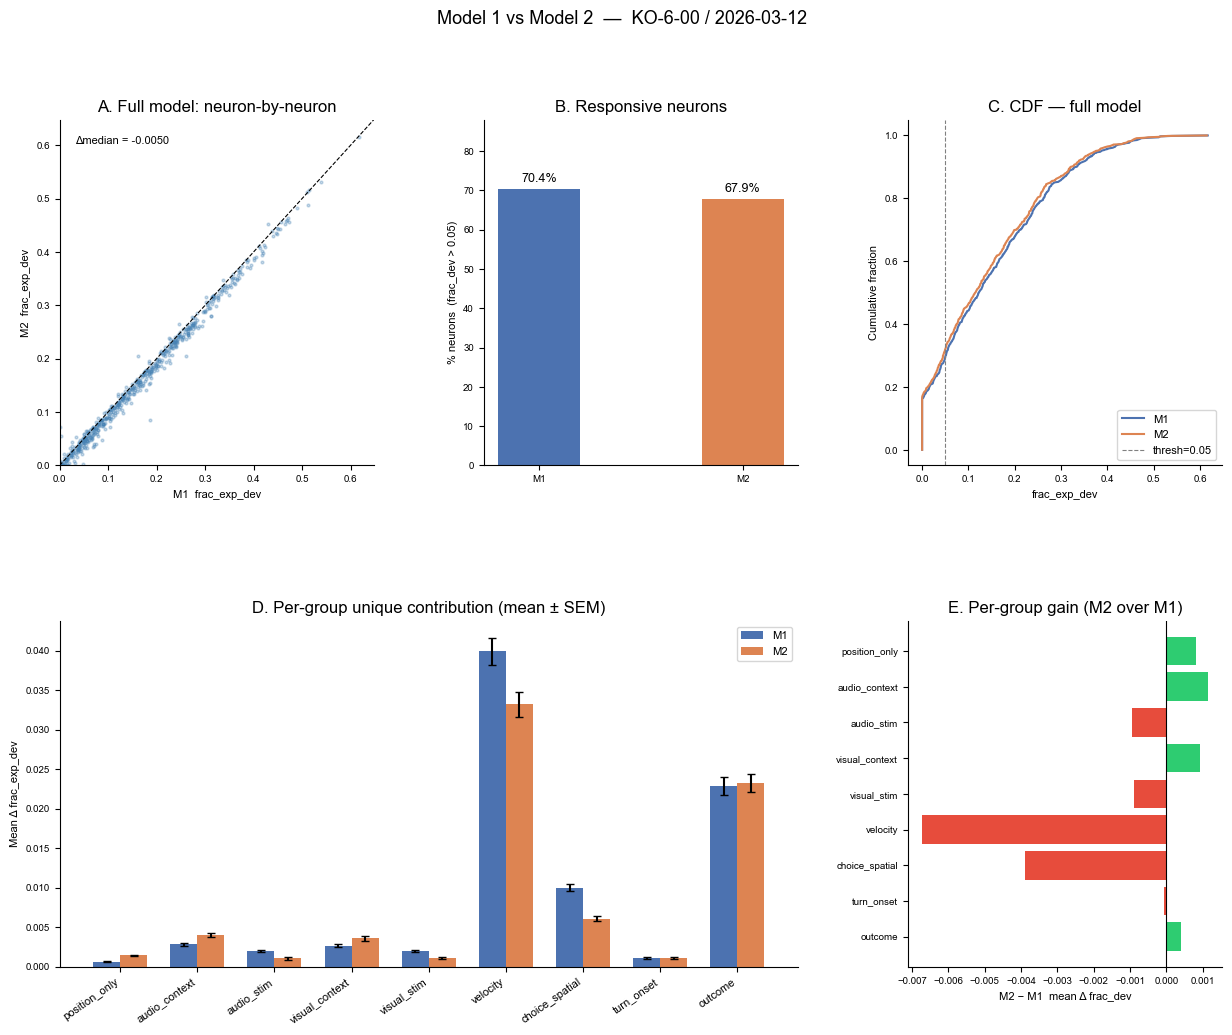


N neurons: 692
M1 median frac_dev: 0.1225
M2 median frac_dev: 0.1147
M2 − M1 (median):   -0.0050


In [ ]:
import os, pickle
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from core.session_pipeline import BASE_DATA_PATH

# ── Config ────────────────────────────────────────────────────────────────────
MOUSE_ID = 'KO-6-00'   # change to your session
DATE     = '2026-03-12'

M1_DIR    = os.path.join(BASE_DATA_PATH, MOUSE_ID, DATE, 'Model_1_results')
M2_DIR    = os.path.join(BASE_DATA_PATH, MOUSE_ID, DATE, 'Model_3_results')

GROUP_ORDER = [
    'position_only', 'audio_context', 'audio_stim',
    'visual_context', 'visual_stim', 'velocity',
    'choice_spatial', 'turn_onset', 'outcome',
]

# ── Load full-model results ───────────────────────────────────────────────────
with open(os.path.join(M1_DIR, 'glm_M1_full.pkl'), 'rb') as f:
    m1 = pickle.load(f)
with open(os.path.join(M2_DIR, 'glm_M2_full.pkl'), 'rb') as f:
    m2 = pickle.load(f)

fd1 = np.clip(m1['test_frac_dev'], 0, None)   # (n_neurons,)
fd2 = np.clip(m2['test_frac_dev'], 0, None)

# ── Load lesion results ───────────────────────────────────────────────────────
with open(os.path.join(M1_DIR, 'glm_M1_lesion_all.pkl'), 'rb') as f:
    les1 = pickle.load(f)
with open(os.path.join(M2_DIR, 'glm_M2_lesion_all.pkl'), 'rb') as f:
    les2 = pickle.load(f)

# delta_frac_dev: group -> (n_neurons,)
delta1 = {g: np.clip(les1['delta_frac_dev'][g], 0, None) for g in GROUP_ORDER}
delta2 = {g: np.clip(les2['delta_frac_dev'][g], 0, None) for g in GROUP_ORDER}

# ── Figure ────────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(15, 11))
fig.suptitle(f'Model 1 vs Model 2  —  {MOUSE_ID} / {DATE}', fontsize=13, y=0.98)
gs  = gridspec.GridSpec(2, 3, figure=fig, hspace=0.45, wspace=0.35)

RESP = 0.05   # responsiveness threshold

# ── Panel A: scatter of full-model frac_dev ───────────────────────────────────
ax = fig.add_subplot(gs[0, 0])
lim = max(fd1.max(), fd2.max()) * 1.05
ax.scatter(fd1, fd2, s=4, alpha=0.3, color='steelblue', rasterized=True)
ax.plot([0, lim], [0, lim], 'k--', lw=0.8, label='unity')
ax.set_xlabel('M1  frac_exp_dev')
ax.set_ylabel('M2  frac_exp_dev')
ax.set_title('A. Full model: neuron-by-neuron')
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
delta_median = np.median(fd2 - fd1)
ax.text(0.05, 0.93, f'Δmedian = {delta_median:+.4f}',
        transform=ax.transAxes, fontsize=8)

# ── Panel B: % responsive neurons ─────────────────────────────────────────────
ax = fig.add_subplot(gs[0, 1])
pct1 = np.mean(fd1 > RESP) * 100
pct2 = np.mean(fd2 > RESP) * 100
bars = ax.bar(['M1', 'M2'], [pct1, pct2], color=['#4C72B0', '#DD8452'], width=0.4)
ax.bar_label(bars, fmt='%.1f%%', padding=3, fontsize=9)
ax.set_ylabel(f'% neurons  (frac_dev > {RESP})')
ax.set_title('B. Responsive neurons')
ax.set_ylim(0, max(pct1, pct2) * 1.25)

# ── Panel C: CDF of frac_dev ──────────────────────────────────────────────────
ax = fig.add_subplot(gs[0, 2])
for fd, label, color in [(fd1, 'M1', '#4C72B0'), (fd2, 'M2', '#DD8452')]:
    sorted_fd = np.sort(fd)
    cdf = np.arange(1, len(sorted_fd) + 1) / len(sorted_fd)
    ax.plot(sorted_fd, cdf, color=color, lw=1.5, label=label)
ax.axvline(RESP, color='gray', ls='--', lw=0.8, label=f'thresh={RESP}')
ax.set_xlabel('frac_exp_dev'); ax.set_ylabel('Cumulative fraction')
ax.set_title('C. CDF — full model')
ax.legend(fontsize=8)

# ── Panel D: per-group delta frac_dev — mean ± SEM ───────────────────────────
ax = fig.add_subplot(gs[1, :2])
x   = np.arange(len(GROUP_ORDER))
w   = 0.35
m1_mean = np.array([delta1[g].mean() for g in GROUP_ORDER])
m2_mean = np.array([delta2[g].mean() for g in GROUP_ORDER])
m1_sem  = np.array([delta1[g].std() / np.sqrt(len(delta1[g])) for g in GROUP_ORDER])
m2_sem  = np.array([delta2[g].std() / np.sqrt(len(delta2[g])) for g in GROUP_ORDER])
ax.bar(x - w/2, m1_mean, w, yerr=m1_sem, label='M1', color='#4C72B0', capsize=3)
ax.bar(x + w/2, m2_mean, w, yerr=m2_sem, label='M2', color='#DD8452', capsize=3)
ax.set_xticks(x); ax.set_xticklabels(GROUP_ORDER, rotation=35, ha='right', fontsize=8)
ax.set_ylabel('Mean Δ frac_exp_dev'); ax.set_title('D. Per-group unique contribution (mean ± SEM)')
ax.legend(fontsize=8)

# ── Panel E: M2 − M1 gain per group ──────────────────────────────────────────
ax = fig.add_subplot(gs[1, 2])
gain = m2_mean - m1_mean
colors = ['#2ECC71' if g >= 0 else '#E74C3C' for g in gain]
ax.barh(GROUP_ORDER, gain, color=colors)
ax.axvline(0, color='k', lw=0.8)
ax.set_xlabel('M2 − M1  mean Δ frac_dev')
ax.set_title('E. Per-group gain (M2 over M1)')
ax.invert_yaxis()

#plt.savefig(f'model1_vs_model2_{MOUSE_ID}_{DATE}.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'\nN neurons: {len(fd1)}')
print(f'M1 median frac_dev: {np.median(fd1):.4f}')
print(f'M2 median frac_dev: {np.median(fd2):.4f}')
print(f'M2 − M1 (median):   {np.median(fd2 - fd1):+.4f}')

Total neurons: 692  |  Responsive: 543
Median coupling contribution: 0.0655
Median total behavioural:     0.0434

Neurons per functional type:
dominant_group
mixed             436
velocity           56
outcome            49
choice_spatial      2


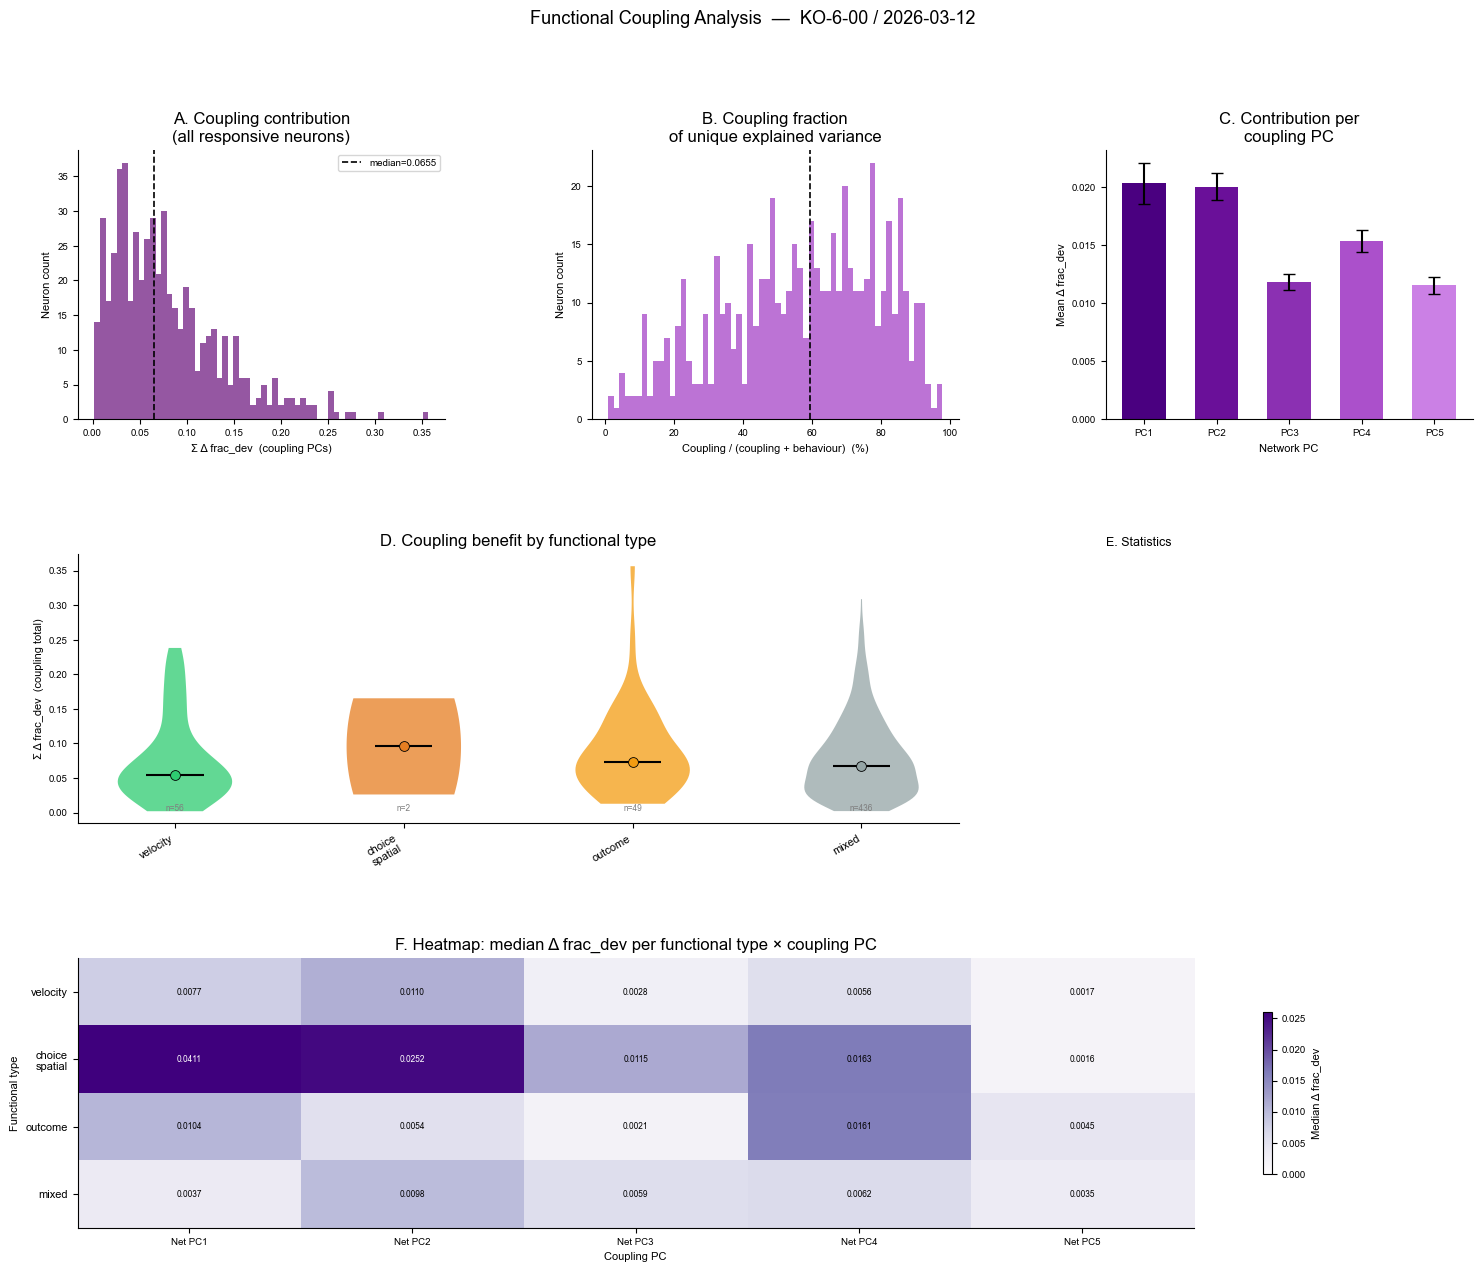


── Median coupling contribution by functional type ──
                coupling_total_median  coupling_total_mean  coupling_total_count  coupling_frac_median  coupling_frac_mean  coupling_frac_count  test_frac_dev_median  test_frac_dev_mean  test_frac_dev_count
dominant_group                                                                                                                                                                                                
choice_spatial                 0.0958               0.0958                     2                0.6399              0.6399                    2                0.2741              0.2741                    2
mixed                          0.0670               0.0785                   436                0.6116              0.5787                  436                0.2455              0.2767                  436
outcome                        0.0729               0.0872                    49                0.4596              0

In [44]:
# ============================================================
# Coupling contribution analysis — example session
# ============================================================
import os, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch
from scipy import stats

from core.session_pipeline import BASE_DATA_PATH

# ── Config ───────────────────────────────────────────────────
MOUSE_ID      = 'KO-6-00'
DATE          = '2026-03-12'
MODEL_NAME    = 'Coupling'
MODEL_TAG     = 'coupling'
MODEL_DIR     = f'{MODEL_NAME}_results'
MODEL_PREFIX  = f'glm_{MODEL_TAG}'
N_PCS         = 5
RESP_THRESH   = 0.05
MIXED_MARGIN  = 0.5

# Functional groups (base model — no coupling)
BEHAV_GROUPS = [
    'position_only', 'audio_context', 'audio_stim',
    'visual_context', 'visual_stim', 'velocity',
    'choice_spatial', 'turn_onset', 'outcome',
]
COUPLING_GROUPS = [f'network_pc{k}' for k in range(1, N_PCS + 1)]
ALL_GROUPS      = BEHAV_GROUPS + COUPLING_GROUPS

GROUP_COLORS = {
    'position_only':  '#9B59B6',
    'audio_context':  '#27AAE1', 'audio_stim':    '#1A7AAF',
    'visual_context': '#EC008C', 'visual_stim':   '#A8005E',
    'velocity':       '#2ECC71',
    'choice_spatial': '#E67E22',
    'turn_onset':     '#E74C3C',
    'outcome':        '#F39C12',
    'mixed':          '#95A5A6',
    # coupling PCs — purple gradient
    'network_pc1': '#4A0080', 'network_pc2': '#6A1099',
    'network_pc3': '#8B30B2', 'network_pc4': '#AB50CB',
    'network_pc5': '#CB80E5',
}
GROUP_LABELS = {g: g.replace('_', '\n') for g in ALL_GROUPS}
GROUP_LABELS.update({'network_pc1': 'Net\nPC1', 'network_pc2': 'Net\nPC2',
                     'network_pc3': 'Net\nPC3', 'network_pc4': 'Net\nPC4',
                     'network_pc5': 'Net\nPC5'})

# ── Load results ─────────────────────────────────────────────
res_dir = os.path.join(BASE_DATA_PATH, MOUSE_ID, DATE, MODEL_DIR)

with open(os.path.join(res_dir, f'{MODEL_PREFIX}_full.pkl'), 'rb') as f:
    full_res = pickle.load(f)
with open(os.path.join(res_dir, f'{MODEL_PREFIX}_lesion_all.pkl'), 'rb') as f:
    les_res  = pickle.load(f)

n_neurons    = len(full_res['test_frac_dev'])
test_fd      = np.clip(full_res['test_frac_dev'], 0, None)
delta_fd     = {g: np.clip(les_res['delta_frac_dev'][g], 0, None)
                for g in les_res['delta_frac_dev']}

# ── Build per-neuron DataFrame ───────────────────────────────
rows = []
for i in range(n_neurons):
    row = {'neuron_idx': i, 'test_frac_dev': test_fd[i]}
    for g in ALL_GROUPS:
        row[f'delta_fd_{g}'] = delta_fd.get(g, np.zeros(n_neurons))[i]
    rows.append(row)

df = pd.DataFrame(rows)
df['is_responsive'] = df['test_frac_dev'] > RESP_THRESH

# ── Coupling total ────────────────────────────────────────────
coupling_cols = [f'delta_fd_{g}' for g in COUPLING_GROUPS]
behav_cols    = [f'delta_fd_{g}' for g in BEHAV_GROUPS]
df['coupling_total']  = df[coupling_cols].sum(axis=1)
df['behavior_total']  = df[behav_cols].sum(axis=1)
df['coupling_frac']   = df['coupling_total'] / (df['coupling_total'] + df['behavior_total'] + 1e-9)

# ── Dominant group (behavioural groups only, from base model) ─
delta_arr  = np.clip(df[behav_cols].values, 0, None)
row_sum    = delta_arr.sum(axis=1, keepdims=True)
row_sum[row_sum == 0] = 1.0
norm_delta = delta_arr / row_sum

dom_idx    = norm_delta.argmax(axis=1)
dom_val    = norm_delta[np.arange(len(norm_delta)), dom_idx]
runner_arr = norm_delta.copy()
runner_arr[np.arange(len(runner_arr)), dom_idx] = -1
rup_val    = runner_arr.max(axis=1)
margin     = dom_val - rup_val

df['dominant_group'] = np.where(
    margin < MIXED_MARGIN,
    'mixed',
    pd.Series(behav_cols, dtype=str).str.replace('delta_fd_', '').values[dom_idx]
)

# Responsive subset
df_resp = df[df['is_responsive']].copy()

print(f'Total neurons: {n_neurons}  |  Responsive: {len(df_resp)}')
print(f'Median coupling contribution: {df_resp["coupling_total"].median():.4f}')
print(f'Median total behavioural:     {df_resp["behavior_total"].median():.4f}')
print(f'\nNeurons per functional type:')
print(df_resp['dominant_group'].value_counts().to_string())

# ============================================================
# FIGURE
# ============================================================
fig = plt.figure(figsize=(18, 14))
fig.suptitle(f'Functional Coupling Analysis  —  {MOUSE_ID} / {DATE}',
             fontsize=13, y=0.98)
gs = gridspec.GridSpec(3, 3, figure=fig, hspace=0.5, wspace=0.4)

FTYPE_ORDER = [g for g in BEHAV_GROUPS + ['mixed']
               if g in df_resp['dominant_group'].unique()]

# ── A: Total coupling delta_fd distribution (all responsive) ──
ax = fig.add_subplot(gs[0, 0])
ax.hist(df_resp['coupling_total'], bins=60, color='#7B2D8B', alpha=0.8, edgecolor='none')
ax.axvline(df_resp['coupling_total'].median(), color='k', lw=1.2, ls='--',
           label=f'median={df_resp["coupling_total"].median():.4f}')
ax.set_xlabel('Σ Δ frac_dev  (coupling PCs)')
ax.set_ylabel('Neuron count')
ax.set_title('A. Coupling contribution\n(all responsive neurons)')
ax.legend(fontsize=7)

# ── B: Coupling fraction of total explained variance ──────────
ax = fig.add_subplot(gs[0, 1])
ax.hist(df_resp['coupling_frac'] * 100, bins=60, color='#AB50CB', alpha=0.8, edgecolor='none')
ax.axvline(df_resp['coupling_frac'].median() * 100, color='k', lw=1.2, ls='--')
ax.set_xlabel('Coupling / (coupling + behaviour)  (%)')
ax.set_ylabel('Neuron count')
ax.set_title('B. Coupling fraction\nof unique explained variance')

# ── C: Per-PC coupling contribution (bar, mean ± SEM) ─────────
ax = fig.add_subplot(gs[0, 2])
pc_means = [df_resp[f'delta_fd_network_pc{k}'].mean() for k in range(1, N_PCS + 1)]
pc_sems  = [df_resp[f'delta_fd_network_pc{k}'].sem()  for k in range(1, N_PCS + 1)]
pc_colors = [GROUP_COLORS[f'network_pc{k}'] for k in range(1, N_PCS + 1)]
x = np.arange(N_PCS)
bars = ax.bar(x, pc_means, yerr=pc_sems, color=pc_colors, capsize=4, width=0.6)
ax.set_xticks(x); ax.set_xticklabels([f'PC{k}' for k in range(1, N_PCS + 1)])
ax.set_xlabel('Network PC'); ax.set_ylabel('Mean Δ frac_dev')
ax.set_title('C. Contribution per\ncoupling PC')

# ── D: Coupling total by functional type (violin) ─────────────
ax = fig.add_subplot(gs[1, :2])
data_by_type = [df_resp[df_resp['dominant_group'] == g]['coupling_total'].values
                for g in FTYPE_ORDER]
parts = ax.violinplot(data_by_type, positions=range(len(FTYPE_ORDER)),
                      showmedians=True, showextrema=False)
for i, (pc, g) in enumerate(zip(parts['bodies'], FTYPE_ORDER)):
    pc.set_facecolor(GROUP_COLORS.get(g, '#888'))
    pc.set_alpha(0.75)
parts['cmedians'].set_color('k'); parts['cmedians'].set_linewidth(1.5)

# Overlay individual medians as dots
for i, g in enumerate(FTYPE_ORDER):
    d = df_resp[df_resp['dominant_group'] == g]['coupling_total'].values
    ax.scatter(i, np.median(d), color=GROUP_COLORS.get(g, '#888'),
               s=50, zorder=5, edgecolors='k', linewidths=0.6)
    n = len(d)
    ax.text(i, ax.get_ylim()[0] if ax.get_ylim()[0] > 0 else 0,
            f'n={n}', ha='center', va='bottom', fontsize=6, color='gray')

ax.set_xticks(range(len(FTYPE_ORDER)))
ax.set_xticklabels([GROUP_LABELS.get(g, g) for g in FTYPE_ORDER],
                   fontsize=8, rotation=30, ha='right')
ax.set_ylabel('Σ Δ frac_dev  (coupling total)')
ax.set_title('D. Coupling benefit by functional type')

# ── E: One-way stats (Kruskal-Wallis + pairwise vs velocity) ──
ax = fig.add_subplot(gs[1, 2])
ax.axis('off')
groups_for_stats = [g for g in FTYPE_ORDER if g not in ('mixed', 'unclassified')]
kw_data = [df_resp[df_resp['dominant_group'] == g]['coupling_total'].values
           for g in groups_for_stats]
if len(kw_data) >= 2 and all(len(d) > 2 for d in kw_data):
    h_stat, p_kw = stats.kruskal(*kw_data)
    lines = [f'Kruskal-Wallis\nH={h_stat:.2f}  p={p_kw:.2e}\n']
    vel_data = df_resp[df_resp['dominant_group'] == 'velocity']['coupling_total'].values
    for g in groups_for_stats:
        if g == 'velocity':
            continue
        d = df_resp[df_resp['dominant_group'] == g]['coupling_total'].values
        if len(d) > 2 and len(vel_data) > 2:
            _, p = stats.mannwhitneyu(d, vel_data, alternative='two-sided')
            lines.append(f'{g[:12]} vs vel:  p={p:.2e}')
    ax.text(0.05, 0.95, '\n'.join(lines), transform=ax.transAxes,
            fontsize=7, va='top', fontfamily='monospace')
ax.set_title('E. Statistics', loc='left', fontsize=9)

# ── F: Heatmap — median Δ frac_dev per (functional type × PC) ─
ax = fig.add_subplot(gs[2, :])
heat_data = np.zeros((len(FTYPE_ORDER), N_PCS))
for i, g in enumerate(FTYPE_ORDER):
    sub = df_resp[df_resp['dominant_group'] == g]
    for k in range(N_PCS):
        heat_data[i, k] = sub[f'delta_fd_network_pc{k+1}'].median()

im = ax.imshow(heat_data, aspect='auto', cmap='Purples',
               vmin=0, vmax=np.percentile(heat_data, 95))
ax.set_xticks(range(N_PCS)); ax.set_xticklabels([f'Net PC{k+1}' for k in range(N_PCS)])
ax.set_yticks(range(len(FTYPE_ORDER)))
ax.set_yticklabels([GROUP_LABELS.get(g, g) for g in FTYPE_ORDER], fontsize=8)
ax.set_xlabel('Coupling PC'); ax.set_ylabel('Functional type')
ax.set_title('F. Heatmap: median Δ frac_dev per functional type × coupling PC')
plt.colorbar(im, ax=ax, label='Median Δ frac_dev', shrink=0.6)

# Annotate cells
for i in range(len(FTYPE_ORDER)):
    for k in range(N_PCS):
        ax.text(k, i, f'{heat_data[i, k]:.4f}', ha='center', va='center',
                fontsize=6, color='white' if heat_data[i, k] > heat_data.max()*0.6 else 'black')

#plt.savefig(f'coupling_analysis_{MOUSE_ID}_{DATE}.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Summary table ─────────────────────────────────────────────
print('\n── Median coupling contribution by functional type ──')
summary = (df_resp.groupby('dominant_group')
           [['coupling_total', 'coupling_frac', 'test_frac_dev']]
           .agg(['median', 'mean', 'count']))
summary.columns = ['_'.join(c) for c in summary.columns]
print(summary.round(4).to_string())

Neurons — total: 692  |  responsive: 386

Median Model 1 frac_dev:   0.2261
Median Coupling frac_dev:  0.3336
Median coupling gain:      +0.0901
% neurons with gain > 0:   99.5%

Neurons per type (Model 1 classification):
dominant_group
velocity          246
outcome            92
mixed              28
choice_spatial     12
audio_stim          5
audio_context       3


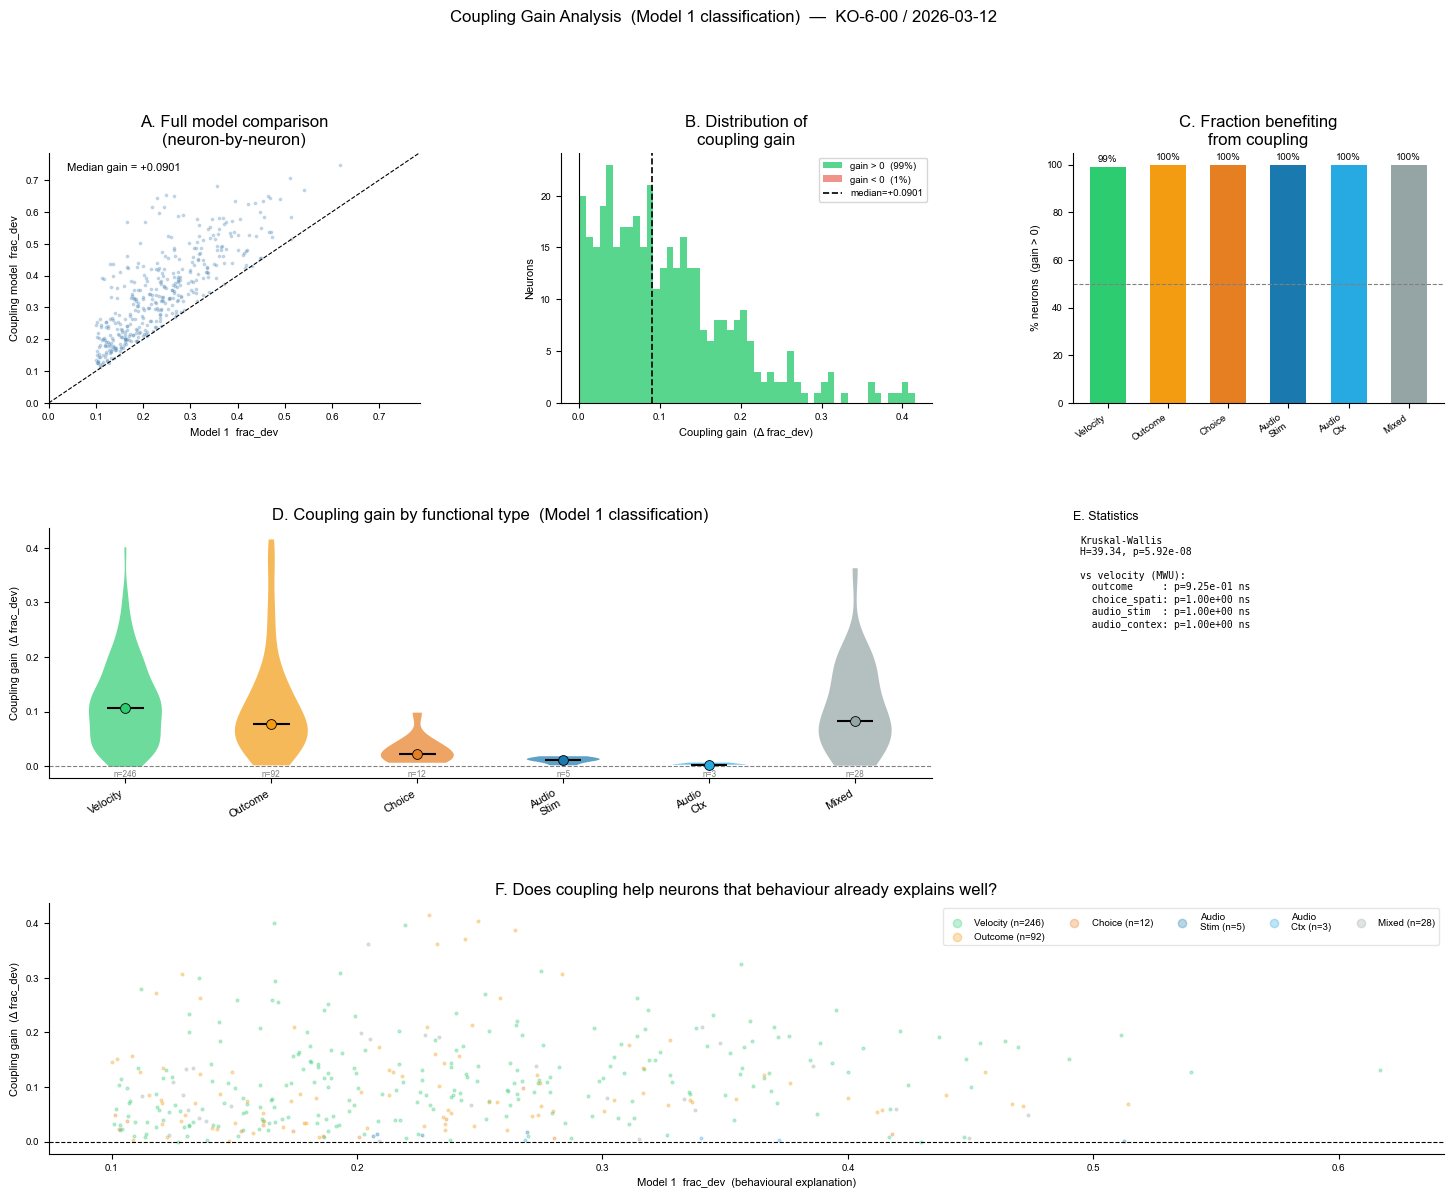


── Coupling gain by functional type (Model 1 classification) ──
                  n  median    mean  pct_positive
dominant_group                                   
velocity        246  0.1070  0.1140        99.187
mixed            28  0.0823  0.1061       100.000
outcome          92  0.0779  0.1100       100.000
choice_spatial   12  0.0217  0.0298       100.000
audio_stim        5  0.0116  0.0114       100.000
audio_context     3  0.0029  0.0042       100.000


In [43]:
# ============================================================
# Coupling gain analysis — using Model 1 classification
# (run while coupling lesion models are still fitting)
# ============================================================

from core.session_pipeline import BASE_DATA_PATH

# ── Config ────────────────────────────────────────────────────
MOUSE_ID     = 'KO-6-00'
DATE         = '2026-03-12'
RESP_THRESH  = 0.1
MIXED_MARGIN = 0.05

BEHAV_GROUPS = [
    'position_only', 'audio_context', 'audio_stim',
    'visual_context', 'visual_stim', 'velocity',
    'choice_spatial', 'turn_onset', 'outcome',
]
GROUP_COLORS = {
    'position_only':  '#9B59B6',
    'audio_context':  '#27AAE1', 'audio_stim':    '#1A7AAF',
    'visual_context': '#EC008C', 'visual_stim':   '#A8005E',
    'velocity':       '#2ECC71',
    'choice_spatial': '#E67E22',
    'turn_onset':     '#E74C3C',
    'outcome':        '#F39C12',
    'mixed':          '#95A5A6',
}
GROUP_LABELS = {
    'position_only': 'Position', 'audio_context': 'Audio\nCtx',
    'audio_stim': 'Audio\nStim', 'visual_context': 'Visual\nCtx',
    'visual_stim': 'Visual\nStim', 'velocity': 'Velocity',
    'choice_spatial': 'Choice', 'turn_onset': 'Turn\nOnset',
    'outcome': 'Outcome', 'mixed': 'Mixed',
}

# ── Load Model 1 results ──────────────────────────────────────
m1_dir = os.path.join(BASE_DATA_PATH, MOUSE_ID, DATE, 'Model_1_results')
with open(os.path.join(m1_dir, 'glm_M1_full.pkl'), 'rb') as f:
    m1_full = pickle.load(f)
with open(os.path.join(m1_dir, 'glm_M1_lesion_all.pkl'), 'rb') as f:
    m1_les  = pickle.load(f)

# ── Load Coupling model full results ──────────────────────────
coup_dir = os.path.join(BASE_DATA_PATH, MOUSE_ID, DATE, 'Coupling_results')
with open(os.path.join(coup_dir, 'glm_coupling_full.pkl'), 'rb') as f:
    coup_full = pickle.load(f)

# ── Build per-neuron DataFrame ────────────────────────────────
n_neurons = len(m1_full['test_frac_dev'])

df = pd.DataFrame({'neuron_idx': np.arange(n_neurons)})
df['fd_model1']   = np.clip(m1_full['test_frac_dev'],   0, None)
df['fd_coupling'] = np.clip(coup_full['test_frac_dev'], 0, None)
df['coupling_gain'] = df['fd_coupling'] - df['fd_model1']   # key metric

for g in BEHAV_GROUPS:
    df[f'delta_fd_{g}'] = np.clip(
        m1_les['delta_frac_dev'].get(g, np.zeros(n_neurons)), 0, None)

df['is_responsive'] = df['fd_model1'] > RESP_THRESH

# ── Dominant group from Model 1 ───────────────────────────────
behav_cols  = [f'delta_fd_{g}' for g in BEHAV_GROUPS]
delta_arr   = df[behav_cols].values.clip(0)
row_sum     = delta_arr.sum(axis=1, keepdims=True)
row_sum[row_sum == 0] = 1.0
norm_delta  = delta_arr / row_sum

dom_idx     = norm_delta.argmax(axis=1)
dom_val     = norm_delta[np.arange(len(norm_delta)), dom_idx]
runner_copy = norm_delta.copy()
runner_copy[np.arange(len(runner_copy)), dom_idx] = -1
rup_val     = runner_copy.max(axis=1)
margin      = dom_val - rup_val

df['dominant_group'] = np.where(
    margin < MIXED_MARGIN,
    'mixed',
    pd.Series(BEHAV_GROUPS, dtype=str).values[dom_idx]
)

df_resp = df[df['is_responsive']].copy()

print(f'Neurons — total: {n_neurons}  |  responsive: {len(df_resp)}')
print(f'\nMedian Model 1 frac_dev:   {df_resp["fd_model1"].median():.4f}')
print(f'Median Coupling frac_dev:  {df_resp["fd_coupling"].median():.4f}')
print(f'Median coupling gain:      {df_resp["coupling_gain"].median():+.4f}')
print(f'% neurons with gain > 0:   {(df_resp["coupling_gain"] > 0).mean()*100:.1f}%')
print(f'\nNeurons per type (Model 1 classification):')
print(df_resp['dominant_group'].value_counts().to_string())

# ── Functional type order (by sample size, keep mixed last) ───
type_counts = df_resp['dominant_group'].value_counts()
FTYPE_ORDER = [g for g in type_counts.index if g != 'mixed']
if 'mixed' in type_counts.index:
    FTYPE_ORDER.append('mixed')

# ============================================================
# FIGURE
# ============================================================
fig = plt.figure(figsize=(18, 13))
fig.suptitle(
    f'Coupling Gain Analysis  (Model 1 classification)  —  {MOUSE_ID} / {DATE}',
    fontsize=12, y=0.99)
gs = gridspec.GridSpec(3, 3, figure=fig, hspace=0.5, wspace=0.38)

# ── A: Model 1 vs Coupling scatter ────────────────────────────
ax = fig.add_subplot(gs[0, 0])
lim = max(df_resp[['fd_model1', 'fd_coupling']].values.max() * 1.05, 0.1)
ax.scatter(df_resp['fd_model1'], df_resp['fd_coupling'],
           s=3, alpha=0.25, color='steelblue', rasterized=True)
ax.plot([0, lim], [0, lim], 'k--', lw=0.8)
ax.set_xlabel('Model 1  frac_dev');  ax.set_ylabel('Coupling model  frac_dev')
ax.set_title('A. Full model comparison\n(neuron-by-neuron)')
ax.set_xlim(0, lim);  ax.set_ylim(0, lim)
med_gain = df_resp['coupling_gain'].median()
ax.text(0.05, 0.93, f'Median gain = {med_gain:+.4f}',
        transform=ax.transAxes, fontsize=8)

# ── B: Coupling gain distribution ─────────────────────────────
ax = fig.add_subplot(gs[0, 1])
gains = df_resp['coupling_gain'].values
ax.hist(gains[gains >= 0], bins=50, color='#2ECC71', alpha=0.8,
        label=f'gain > 0  ({(gains>0).mean()*100:.0f}%)', edgecolor='none')
ax.hist(gains[gains <  0], bins=30, color='#E74C3C', alpha=0.6,
        label=f'gain < 0  ({(gains<0).mean()*100:.0f}%)', edgecolor='none')
ax.axvline(0, color='k', lw=0.8)
ax.axvline(np.median(gains), color='k', lw=1.2, ls='--',
           label=f'median={np.median(gains):+.4f}')
ax.set_xlabel('Coupling gain  (Δ frac_dev)');  ax.set_ylabel('Neurons')
ax.set_title('B. Distribution of\ncoupling gain')
ax.legend(fontsize=7)

# ── C: % neurons with positive coupling gain per type ─────────
ax = fig.add_subplot(gs[0, 2])
pct_pos = [
    (df_resp[df_resp['dominant_group'] == g]['coupling_gain'] > 0).mean() * 100
    for g in FTYPE_ORDER
]
bar_colors = [GROUP_COLORS.get(g, '#888') for g in FTYPE_ORDER]
bars = ax.bar(range(len(FTYPE_ORDER)), pct_pos, color=bar_colors, width=0.6)
ax.bar_label(bars, fmt='%.0f%%', padding=2, fontsize=7)
ax.axhline(50, color='gray', ls='--', lw=0.8)
ax.set_xticks(range(len(FTYPE_ORDER)))
ax.set_xticklabels([GROUP_LABELS.get(g, g) for g in FTYPE_ORDER],
                   rotation=35, ha='right', fontsize=7)
ax.set_ylabel('% neurons  (gain > 0)')
ax.set_title('C. Fraction benefiting\nfrom coupling')

# ── D: Coupling gain by functional type (violin) ──────────────
ax = fig.add_subplot(gs[1, :2])
vdata = [df_resp[df_resp['dominant_group'] == g]['coupling_gain'].values
         for g in FTYPE_ORDER]
parts = ax.violinplot(vdata, positions=range(len(FTYPE_ORDER)),
                      showmedians=True, showextrema=False)
for pc, g in zip(parts['bodies'], FTYPE_ORDER):
    pc.set_facecolor(GROUP_COLORS.get(g, '#888'));  pc.set_alpha(0.7)
parts['cmedians'].set_color('k');  parts['cmedians'].set_linewidth(1.5)
ax.axhline(0, color='gray', lw=0.8, ls='--')

for i, (g, d) in enumerate(zip(FTYPE_ORDER, vdata)):
    ax.scatter(i, np.median(d), s=50, zorder=5,
               color=GROUP_COLORS.get(g, '#888'), edgecolors='k', lw=0.6)
    ax.text(i, ax.get_ylim()[0], f'n={len(d)}',
            ha='center', va='bottom', fontsize=6, color='gray')

ax.set_xticks(range(len(FTYPE_ORDER)))
ax.set_xticklabels([GROUP_LABELS.get(g, g) for g in FTYPE_ORDER],
                   rotation=30, ha='right', fontsize=8)
ax.set_ylabel('Coupling gain  (Δ frac_dev)');
ax.set_title('D. Coupling gain by functional type  (Model 1 classification)')

# ── E: Stats ───────────────────────────────────────────────────
ax = fig.add_subplot(gs[1, 2]);  ax.axis('off')
stat_groups = [g for g in FTYPE_ORDER if g != 'mixed']
kw_data = [df_resp[df_resp['dominant_group'] == g]['coupling_gain'].values
           for g in stat_groups]
if len(kw_data) >= 2 and all(len(d) > 2 for d in kw_data):
    h, p_kw = stats.kruskal(*kw_data)
    lines = [f'Kruskal-Wallis', f'H={h:.2f}, p={p_kw:.2e}', '']
    # Pairwise vs velocity (expected lowest coupling)
    vel_d = df_resp[df_resp['dominant_group'] == 'velocity']['coupling_gain'].values
    lines.append('vs velocity (MWU):')
    for g in stat_groups:
        if g == 'velocity': continue
        d = df_resp[df_resp['dominant_group'] == g]['coupling_gain'].values
        if len(d) > 2 and len(vel_d) > 2:
            _, p = stats.mannwhitneyu(d, vel_d, alternative='greater')
            sig = '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else 'ns'
            lines.append(f'  {g[:12]:<12}: p={p:.2e} {sig}')
    ax.text(0.02, 0.97, '\n'.join(lines), transform=ax.transAxes,
            fontsize=7, va='top', fontfamily='monospace')
ax.set_title('E. Statistics', loc='left', fontsize=9)

# ── F: Scatter — Model 1 frac_dev vs coupling gain, by type ───
ax = fig.add_subplot(gs[2, :])
for g in FTYPE_ORDER:
    sub = df_resp[df_resp['dominant_group'] == g]
    ax.scatter(sub['fd_model1'], sub['coupling_gain'],
               s=4, alpha=0.3, color=GROUP_COLORS.get(g, '#888'),
               label=f'{GROUP_LABELS.get(g,g)} (n={len(sub)})', rasterized=True)
ax.axhline(0, color='k', lw=0.8, ls='--')
ax.set_xlabel('Model 1  frac_dev  (behavioural explanation)')
ax.set_ylabel('Coupling gain  (Δ frac_dev)')
ax.set_title('F. Does coupling help neurons that behaviour already explains well?')
leg = ax.legend(fontsize=7, ncol=5, loc='upper right',
                markerscale=3, framealpha=0.5)

plt.savefig(f'coupling_gain_{MOUSE_ID}_{DATE}.png', dpi=150, bbox_inches='tight')
plt.show()

# ── Summary table ─────────────────────────────────────────────
print('\n── Coupling gain by functional type (Model 1 classification) ──')
summary = (df_resp.groupby('dominant_group')['coupling_gain']
           .agg(n='count', median='median', mean='mean',
                pct_positive=lambda x: (x > 0).mean() * 100)
           .sort_values('median', ascending=False))
print(summary.round(4).to_string())

Neurons: 692
Responsive (M1 threshold): 386

── Full-model frac_dev summary (responsive neurons) ──
  Model 1 (base)                  median=0.2261  >0.05: 100.0%
  Model 2 (+coupling)             median=0.3330  >0.05: 99.5%
  Model 3 (+stim/choice)          median=0.3336  >0.05: 100.0%


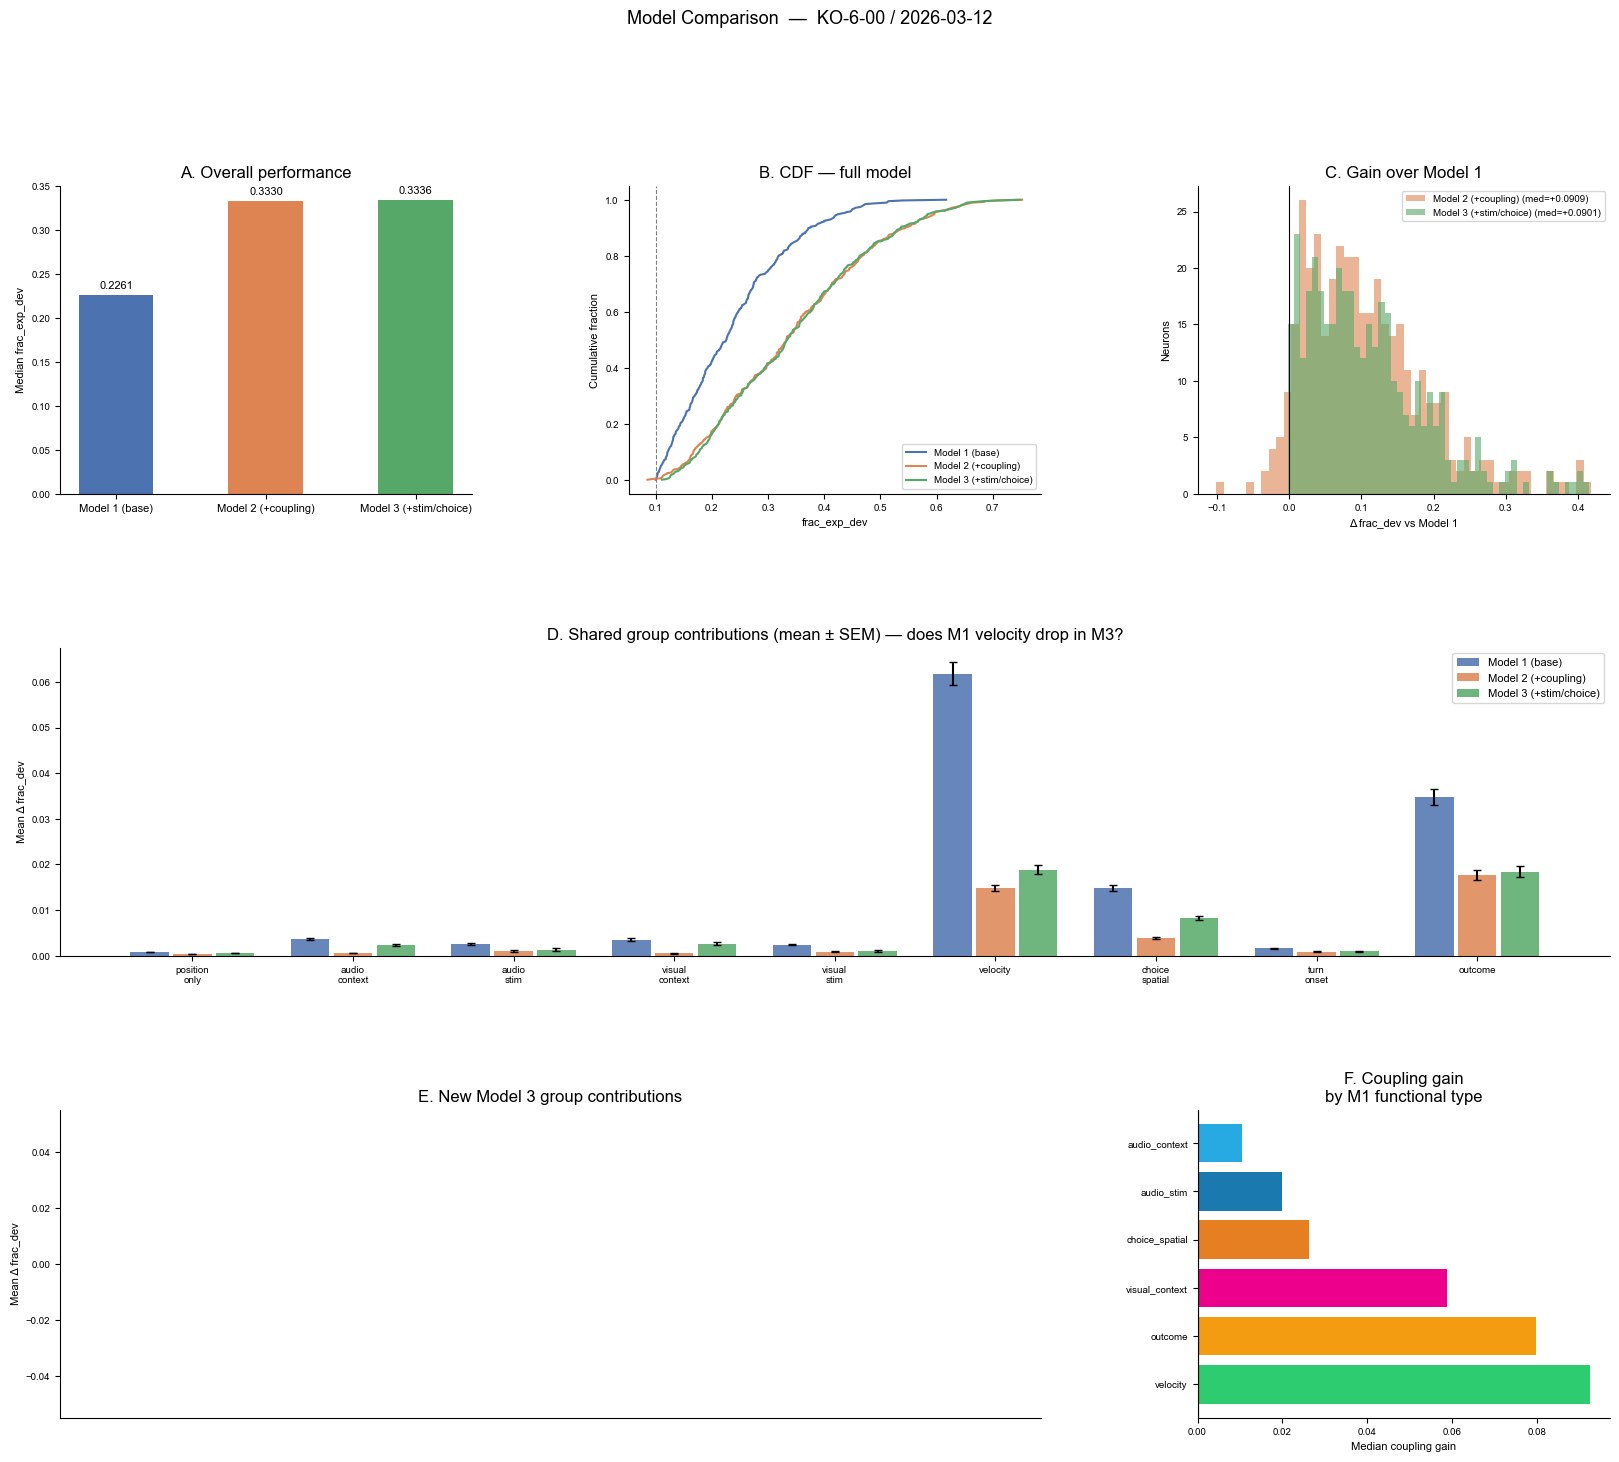

In [46]:
# ============================================================
# Cross-model comparison: Model 1 vs Model 2 (coupling) vs Model 3
# ============================================================
import os, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import stats

from core.session_pipeline import BASE_DATA_PATH

# ── Config ────────────────────────────────────────────────────
MOUSE_ID    = 'KO-6-00'
DATE        = '2026-03-12'
RESP_THRESH = 0.1

MODELS = {
    'Model 1\n(base)': {
        'dir':    'Model_1_results',
        'prefix': 'glm_M1',
        'color':  '#4C72B0',
    },
    'Model 2\n(+coupling)': {
        'dir':    'Model_2_results',
        'prefix': 'glm_M2',
        'color':  '#DD8452',
    },
    'Model 3\n(+stim/choice)': {
        'dir':    'Coupling_results',
        'prefix': 'glm_coupling',
        'color':  '#55A868',
    },
}

# ── Groups per model ──────────────────────────────────────────
M1_GROUPS = [
    'position_only', 'audio_context', 'audio_stim',
    'visual_context', 'visual_stim', 'velocity',
    'choice_spatial', 'turn_onset', 'outcome',
]
M2_EXTRA   = [f'network_pc{k}' for k in range(1, 6)]
M3_EXTRA   = [
    'audio_context_temporal', 'audio_stim_temporal',
    'visual_context_temporal', 'visual_stim_temporal',
    'pre_turn', 'visual_choice', 'audio_choice',
]
M3_ALL_GROUPS = M1_GROUPS + M3_EXTRA

GROUP_COLORS = {
    'position_only': '#9B59B6', 'audio_context': '#27AAE1', 'audio_stim': '#1A7AAF',
    'visual_context': '#EC008C', 'visual_stim': '#A8005E', 'velocity': '#2ECC71',
    'choice_spatial': '#E67E22', 'turn_onset': '#E74C3C', 'outcome': '#F39C12',
    'audio_context_temporal': '#0E6494', 'audio_stim_temporal': '#1A9ED4',
    'visual_context_temporal': '#7B003E', 'visual_stim_temporal': '#C0005F',
    'pre_turn': '#B03060', 'visual_choice': '#FF6600', 'audio_choice': '#00AACC',
    **{f'network_pc{k}': c for k, c in enumerate(
        ['#4A0080','#6A1099','#8B30B2','#AB50CB','#CB80E5'], 1)},
}

# ── Load results ──────────────────────────────────────────────
data = {}
for label, cfg in MODELS.items():
    res_dir = os.path.join(BASE_DATA_PATH, MOUSE_ID, DATE, cfg['dir'])
    full_path = os.path.join(res_dir, f'{cfg["prefix"]}_full.pkl')
    les_path  = os.path.join(res_dir, f'{cfg["prefix"]}_lesion_all.pkl')

    if not os.path.exists(full_path):
        print(f'[MISSING] {full_path}')
        data[label] = None
        continue

    with open(full_path, 'rb') as f:
        full = pickle.load(f)
    les = None
    if os.path.exists(les_path):
        with open(les_path, 'rb') as f:
            les = pickle.load(f)
    else:
        print(f'[NO LESIONS] {les_path}')

    data[label] = {'full': full, 'les': les, 'cfg': cfg}

available = {k: v for k, v in data.items() if v is not None}
n_neurons  = len(next(iter(available.values()))['full']['test_frac_dev'])
print(f'Neurons: {n_neurons}')

# ── Per-neuron DataFrame ──────────────────────────────────────
rows = []
for i in range(n_neurons):
    row = {'neuron_idx': i}
    for label, d in available.items():
        fd = float(np.clip(d['full']['test_frac_dev'][i], 0, None))
        row[f'fd_{label}'] = fd
        if d['les'] is not None:
            for g, arr in d['les']['delta_frac_dev'].items():
                row[f'delta_{label}_{g}'] = float(np.clip(arr[i], 0, None))
    rows.append(row)

df = pd.DataFrame(rows)
m1_label = [k for k in available if 'Model 1' in k][0]
df['responsive'] = df[f'fd_{m1_label}'] > RESP_THRESH
df_resp = df[df['responsive']].copy()
print(f'Responsive (M1 threshold): {len(df_resp)}')

# ── Print summary ─────────────────────────────────────────────
print('\n── Full-model frac_dev summary (responsive neurons) ──')
for label in available:
    col = f'fd_{label}'
    if col in df_resp:
        med = df_resp[col].median()
        pct = (df_resp[col] > RESP_THRESH).mean() * 100
        print(f'  {label.replace(chr(10)," "):30s}  median={med:.4f}  '
              f'>0.05: {pct:.1f}%')

# ============================================================
# FIGURE
# ============================================================
fig = plt.figure(figsize=(20, 16))
fig.suptitle(f'Model Comparison  —  {MOUSE_ID} / {DATE}', fontsize=13, y=0.99)
gs = gridspec.GridSpec(3, 3, figure=fig, hspace=0.5, wspace=0.38)

labels   = list(available.keys())
colors   = [available[l]['cfg']['color'] for l in labels]
fd_cols  = [f'fd_{l}' for l in labels]

# ── A: Median frac_dev per model ──────────────────────────────
ax = fig.add_subplot(gs[0, 0])
medians = [df_resp[c].median() if c in df_resp else np.nan for c in fd_cols]
bars = ax.bar(range(len(labels)), medians, color=colors, width=0.5)
ax.bar_label(bars, fmt='%.4f', padding=3, fontsize=8)
ax.set_xticks(range(len(labels)))
ax.set_xticklabels([l.replace('\n', ' ') for l in labels], fontsize=8)
ax.set_ylabel('Median frac_exp_dev'); ax.set_title('A. Overall performance')

# ── B: CDF comparison ─────────────────────────────────────────
ax = fig.add_subplot(gs[0, 1])
for label, color in zip(labels, colors):
    col = f'fd_{label}'
    if col not in df_resp: continue
    s = np.sort(df_resp[col].values)
    ax.plot(s, np.arange(1, len(s)+1)/len(s),
            color=color, lw=1.5, label=label.replace('\n',' '))
ax.axvline(RESP_THRESH, color='gray', ls='--', lw=0.8)
ax.set_xlabel('frac_exp_dev'); ax.set_ylabel('Cumulative fraction')
ax.set_title('B. CDF — full model'); ax.legend(fontsize=7)

# ── C: Gain over Model 1 (scatter) ───────────────────────────
ax = fig.add_subplot(gs[0, 2])
m1_col = f'fd_{m1_label}'
for label, color in zip(labels, colors):
    if label == m1_label: continue
    col = f'fd_{label}'
    if col not in df_resp: continue
    gain = df_resp[col] - df_resp[m1_col]
    ax.hist(gain, bins=50, alpha=0.6, color=color,
            label=f'{label.replace(chr(10)," ")} (med={gain.median():+.4f})',
            edgecolor='none')
ax.axvline(0, color='k', lw=0.8)
ax.set_xlabel('Δ frac_dev vs Model 1'); ax.set_ylabel('Neurons')
ax.set_title('C. Gain over Model 1'); ax.legend(fontsize=7)

# ── D: Shared M1 group delta_fds across models ────────────────
ax = fig.add_subplot(gs[1, :])
x = np.arange(len(M1_GROUPS))
n_models_with_les = sum(1 for l in labels
                        if available[l]['les'] is not None
                        and f'delta_{l}_{M1_GROUPS[0]}' in df_resp.columns)
bar_w = 0.8 / max(n_models_with_les, 1)
offset = -(bar_w * (n_models_with_les - 1)) / 2

i_bar = 0
for label, color in zip(labels, colors):
    cols = [f'delta_{label}_{g}' for g in M1_GROUPS]
    if not all(c in df_resp.columns for c in cols): continue
    means = [df_resp[c].mean() for c in cols]
    sems  = [df_resp[c].sem()  for c in cols]
    ax.bar(x + offset + i_bar * bar_w, means, bar_w * 0.9,
           yerr=sems, color=color, alpha=0.85, capsize=3,
           label=label.replace('\n',' '))
    i_bar += 1

ax.set_xticks(x)
ax.set_xticklabels([g.replace('_', '\n') for g in M1_GROUPS], fontsize=7)
ax.set_ylabel('Mean Δ frac_dev'); ax.set_title('D. Shared group contributions (mean ± SEM) — does M1 velocity drop in M3?')
ax.legend(fontsize=8)

# ── E: New M3 group contributions ─────────────────────────────
m3_label = next((l for l in labels if 'stim/choice' in l), None)
if m3_label and available[m3_label]['les'] is not None:
    ax = fig.add_subplot(gs[2, :2])
    new_groups_available = [g for g in M3_EXTRA
                            if f'delta_{m3_label}_{g}' in df_resp.columns]
    means = [df_resp[f'delta_{m3_label}_{g}'].mean() for g in new_groups_available]
    sems  = [df_resp[f'delta_{m3_label}_{g}'].sem()  for g in new_groups_available]
    bar_colors = [GROUP_COLORS.get(g, '#888') for g in new_groups_available]
    bars = ax.bar(range(len(new_groups_available)), means, yerr=sems,
                  color=bar_colors, capsize=4, width=0.6)
    ax.set_xticks(range(len(new_groups_available)))
    ax.set_xticklabels([g.replace('_', '\n') for g in new_groups_available],
                       fontsize=7, rotation=30, ha='right')
    ax.set_ylabel('Mean Δ frac_dev'); ax.set_title('E. New Model 3 group contributions')

# ── F: M2 coupling contribution by M1 functional type ─────────
m2_label = next((l for l in labels if 'coupling' in l.lower()), None)
if m2_label and available[m2_label]['les'] is not None:
    ax = fig.add_subplot(gs[2, 2])
    # Use M1 dominant group for classification
    m1_delta_cols = [f'delta_{m1_label}_{g}' for g in M1_GROUPS]
    if all(c in df_resp.columns for c in m1_delta_cols):
        delta_arr  = df_resp[m1_delta_cols].values.clip(0)
        row_sum    = delta_arr.sum(axis=1, keepdims=True)
        row_sum[row_sum == 0] = 1.0
        dom_idx    = (delta_arr / row_sum).argmax(axis=1)
        df_resp    = df_resp.copy()
        df_resp['dom_group_m1'] = [M1_GROUPS[i] for i in dom_idx]

        coup_cols = [f'delta_{m2_label}_{g}' for g in M2_EXTRA
                     if f'delta_{m2_label}_{g}' in df_resp.columns]
        if coup_cols:
            df_resp['coupling_total'] = df_resp[coup_cols].sum(axis=1)
            medians_by_type = df_resp.groupby('dom_group_m1')['coupling_total'].median().sort_values(ascending=False)
            bar_colors = [GROUP_COLORS.get(g, '#888') for g in medians_by_type.index]
            ax.barh(medians_by_type.index, medians_by_type.values, color=bar_colors)
            ax.set_xlabel('Median coupling gain'); ax.axvline(0, color='k', lw=0.8)
            ax.set_title('F. Coupling gain\nby M1 functional type')

plt.savefig(f'model_comparison_{MOUSE_ID}_{DATE}.png', dpi=150, bbox_inches='tight')
plt.show()

  Loaded base
  Loaded ctx_choice
  Loaded coupling

Total neurons: 692
  Model 1 (base)                  n_resp= 373  median FDE=0.2216
  M1 + Ctx×Choice                 n_resp= 367  median FDE=0.2265
  M1 + Coupling                   n_resp= 461  median FDE=0.3329


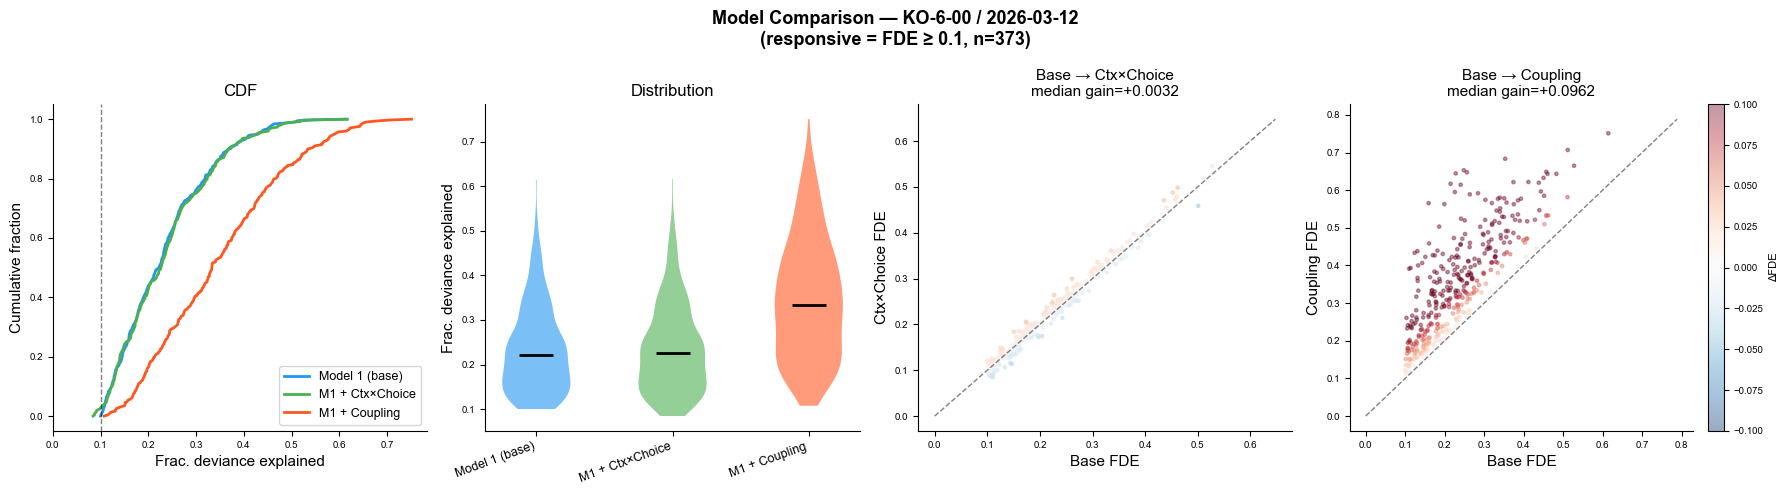

In [47]:
# ── Point these at your saved comparison results ──────────────────────────────
MOUSE_ID       = 'KO-6-00'
DATE           = '2026-03-12'
BASE_DATA_PATH = '/Volumes/Akhil Data/Akhil/ProcessedData'
FDE_THRESHOLD  = 0.1

CONFIGS = {
    'base':       {'label': 'Model 1 (base)',   'color': '#2196F3'},
    'ctx_choice': {'label': 'M1 + Ctx×Choice',  'color': '#4CAF50'},
    'coupling':   {'label': 'M1 + Coupling',     'color': '#FF5722'},
}

# ── Load saved full-model results ─────────────────────────────────────────────
comp_dir = os.path.join(BASE_DATA_PATH, MOUSE_ID, DATE, 'comparison')

all_results = {}
for name in CONFIGS:
    path = os.path.join(comp_dir, f'glm_{name}_full.pkl')
    with open(path, 'rb') as f:
        all_results[name] = pickle.load(f)
    print(f'  Loaded {name}')

# ── Extract FDE vectors ───────────────────────────────────────────────────────
fde       = {name: np.asarray(res['test_frac_dev']) for name, res in all_results.items()}
n_neurons = len(fde['base'])
resp_mask = fde['base'] >= FDE_THRESHOLD
n_resp    = {name: int(np.sum(v >= FDE_THRESHOLD)) for name, v in fde.items()}

print(f'\nTotal neurons: {n_neurons}')
for name, cfg in CONFIGS.items():
    med = float(np.nanmedian(fde[name][resp_mask]))
    print(f'  {cfg["label"]:30s}  n_resp={n_resp[name]:4d}  median FDE={med:.4f}')

# ── Figure ────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
fig.suptitle(
    f'Model Comparison — {MOUSE_ID} / {DATE}\n'
    f'(responsive = FDE ≥ {FDE_THRESHOLD}, n={n_resp["base"]})',
    fontsize=13, fontweight='bold',
)

names  = list(CONFIGS.keys())
labels = [CONFIGS[n]['label'] for n in names]
colors = [CONFIGS[n]['color'] for n in names]

# Panel 1: CDF
ax = axes[0]
for name, lbl, col in zip(names, labels, colors):
    x = np.sort(fde[name][resp_mask])
    y = np.linspace(0, 1, len(x))
    ax.plot(x, y, color=col, lw=2, label=lbl)
ax.axvline(FDE_THRESHOLD, color='k', ls='--', lw=1, alpha=0.5)
ax.set_xlabel('Frac. deviance explained', fontsize=11)
ax.set_ylabel('Cumulative fraction', fontsize=11)
ax.set_title('CDF', fontsize=12)
ax.legend(fontsize=9, loc='lower right')
ax.set_xlim(0, None)

# Panel 2: Violin
ax = axes[1]
vparts = ax.violinplot(
    [fde[n][resp_mask] for n in names],
    positions=range(len(names)),
    showmedians=True, showextrema=False,
)
for pc, col in zip(vparts['bodies'], colors):
    pc.set_facecolor(col)
    pc.set_alpha(0.6)
vparts['cmedians'].set_color('black')
vparts['cmedians'].set_linewidth(2)
ax.set_xticks(range(len(names)))
ax.set_xticklabels(labels, rotation=20, ha='right', fontsize=9)
ax.set_ylabel('Frac. deviance explained', fontsize=11)
ax.set_title('Distribution', fontsize=12)

# Panel 3: Scatter — Base vs Ctx×Choice
ax = axes[2]
x3, y3   = fde['base'][resp_mask], fde['ctx_choice'][resp_mask]
delta3   = y3 - x3
ax.scatter(x3, y3, s=6, alpha=0.4, c=delta3, cmap='RdBu_r', vmin=-0.1, vmax=0.1)
lim = max(x3.max(), y3.max()) * 1.05
ax.plot([0, lim], [0, lim], 'k--', lw=1, alpha=0.5)
ax.set_xlabel('Base FDE', fontsize=11)
ax.set_ylabel('Ctx×Choice FDE', fontsize=11)
ax.set_title(f'Base → Ctx×Choice\nmedian gain={np.nanmedian(delta3):+.4f}', fontsize=11)

# Panel 4: Scatter — Base vs Coupling
ax = axes[3]
x4, y4   = fde['base'][resp_mask], fde['coupling'][resp_mask]
delta4   = y4 - x4
sc = ax.scatter(x4, y4, s=6, alpha=0.4, c=delta4, cmap='RdBu_r', vmin=-0.1, vmax=0.1)
lim = max(x4.max(), y4.max()) * 1.05
ax.plot([0, lim], [0, lim], 'k--', lw=1, alpha=0.5)
ax.set_xlabel('Base FDE', fontsize=11)
ax.set_ylabel('Coupling FDE', fontsize=11)
ax.set_title(f'Base → Coupling\nmedian gain={np.nanmedian(delta4):+.4f}', fontsize=11)
fig.colorbar(sc, ax=ax, label='ΔFDE', fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()